# Dashboard de portafolio conductual
**Proyecto A — Problema de decisión secuencial con el marco de Powell**

Este notebook es el entregable completo:

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | Datos: 24 ETFs, retornos mensuales 2008–2026 |
| 2 | Modelo de Powell (los cinco elementos) |
| 3 | Parte 1: cuestionario y perfil de prospect theory |
| 4 | Parte 2: portafolio MILP media-CVaR con Gurobi |
| 5 | Escenarios: bootstrap por bloques y números aleatorios comunes |
| 6 | Parte 3: simulador y políticas |
| 7 | Ajuste de parámetros (semilla de ajuste) |
| 8 | Evaluación final (1000 escenarios, semilla de evaluación) |
| 9 | Sensibilidad y recomendación |
| 10 | Dashboard de Streamlit |

**Cómo correrlo.** En Jupyter, VS Code/Antigravity o Google Colab: ejecuta todas las celdas desde la carpeta del repositorio. La licencia restringida que trae `pip install gurobipy` alcanza (el modelo más grande tiene unas 275 variables). La corrida completa tarda unos 20–40 minutos; casi todo ese tiempo es la política CFA, que resuelve el MILP decenas de miles de veces.

**Arquitectura.** Toda la lógica vive en el paquete `core/`, que este notebook escribe a disco con `%%writefile`. El notebook y la app de Streamlit importan exactamente el mismo código, así que no pueden contradecirse. Las celdas de prueba (`assert`) verifican el comportamiento a través de la interfaz pública de `core`.

## 0. Preparación

In [1]:
%pip install -q -r requirements.txt

In [2]:
import os
os.makedirs("core", exist_ok=True)
os.makedirs("data", exist_ok=True)
with open("core/__init__.py", "w", encoding="utf-8") as fh:
    fh.write('"""Paquete del proyecto (la interfaz pública se escribe en la sección 6)."""\n')

%load_ext autoreload
%autoreload 2

import time, json
from dataclasses import replace
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display, Markdown

if os.environ.get("PLOTLY_RENDERER"):      # p. ej. "png" para exportar con gráficos estáticos
    pio.renderers.default = os.environ["PLOTLY_RENDERER"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Datos

Universo de **24 ETFs en 5 clases de activo**. Las clases hacen de "sector" para el tope de peso por sector del MILP.

| Clase | ETFs |
|---|---|
| Acciones EE.UU. (sectores) | XLK, XLF, XLV, XLE, XLI, XLY, XLP, XLU, XLB |
| Acciones internacionales | EFA, EEM, VGK, EWJ |
| Renta fija | TLT, IEF, SHY, LQD, HYG, TIP |
| Activos reales | VNQ, GLD, SLV, DBC |
| Efectivo | BIL |

Usamos precios diarios ajustados (dividendos incluidos) desde diciembre de 2007 hasta el último mes completo (octubre de 2026). El retorno de cada mes es el último precio del mes dividido por el último precio del mes anterior, menos 1. Son unos 226 meses, que incluyen la crisis de 2008, el COVID y el año 2022. BIL (letras del Tesoro de 1–3 meses) es el activo de efectivo: puede entrar en el portafolio y es el refugio del vendedor en pánico.

In [3]:
%%writefile core/data.py
"""Datos: universo de ETFs, descarga con yfinance y retornos mensuales."""
import numpy as np
import pandas as pd

UNIVERSE = {
    # Acciones de EE.UU. por sector
    "XLK": "Acciones EE.UU.", "XLF": "Acciones EE.UU.", "XLV": "Acciones EE.UU.",
    "XLE": "Acciones EE.UU.", "XLI": "Acciones EE.UU.", "XLY": "Acciones EE.UU.",
    "XLP": "Acciones EE.UU.", "XLU": "Acciones EE.UU.", "XLB": "Acciones EE.UU.",
    # Acciones internacionales
    "EFA": "Acciones internacionales", "EEM": "Acciones internacionales",
    "VGK": "Acciones internacionales", "EWJ": "Acciones internacionales",
    # Renta fija
    "TLT": "Renta fija", "IEF": "Renta fija", "SHY": "Renta fija",
    "LQD": "Renta fija", "HYG": "Renta fija", "TIP": "Renta fija",
    # Activos reales
    "VNQ": "Activos reales", "GLD": "Activos reales", "SLV": "Activos reales", "DBC": "Activos reales",
    # Efectivo
    "BIL": "Efectivo",
}

NAMES = {
    "XLK": "Tecnología EE.UU.", "XLF": "Financiero EE.UU.", "XLV": "Salud EE.UU.",
    "XLE": "Energía EE.UU.", "XLI": "Industrial EE.UU.", "XLY": "Consumo discrecional EE.UU.",
    "XLP": "Consumo básico EE.UU.", "XLU": "Servicios públicos EE.UU.", "XLB": "Materiales EE.UU.",
    "EFA": "Desarrollados ex-EE.UU.", "EEM": "Mercados emergentes", "VGK": "Europa", "EWJ": "Japón",
    "TLT": "Bonos del Tesoro 20+ años", "IEF": "Bonos del Tesoro 7-10 años", "SHY": "Bonos del Tesoro 1-3 años",
    "LQD": "Bonos corporativos grado de inversión", "HYG": "Bonos de alto rendimiento",
    "TIP": "Bonos indexados a inflación", "VNQ": "Bienes raíces (REITs)", "GLD": "Oro", "SLV": "Plata",
    "DBC": "Materias primas", "BIL": "Letras del Tesoro 1-3 meses (efectivo)",
}

ASSET_CLASSES = ["Acciones EE.UU.", "Acciones internacionales", "Renta fija", "Activos reales", "Efectivo"]
CASH = "BIL"
START = "2007-12-01"   # el primer retorno mensual es enero de 2008
END = "2026-11-01"     # fecha exclusiva: el último precio es de octubre de 2026


def download_prices(tickers=None, start=START, end=END):
    """Precios diarios de cierre ajustados (dividendos y splits)."""
    import yfinance as yf
    tickers = list(tickers or UNIVERSE)
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
    prices = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
    missing = [t for t in tickers if t not in prices.columns]
    if missing:
        raise RuntimeError(f"yfinance no devolvió datos para: {missing}")
    return prices[tickers].sort_index()


def monthly_returns(prices):
    """Retornos simples mensuales a partir del último precio de cada mes."""
    try:
        month_end = prices.resample("ME").last()
    except ValueError:          # pandas < 2.2
        month_end = prices.resample("M").last()
    rets = month_end.pct_change(fill_method=None).iloc[1:]
    return rets.dropna(how="any")


def save_returns(rets, path="data/monthly_returns.csv"):
    rets.to_csv(path, index_label="date")


def load_returns(path="data/monthly_returns.csv"):
    rets = pd.read_csv(path, index_col=0, parse_dates=True)
    return rets[[t for t in UNIVERSE if t in rets.columns]]

Overwriting core/data.py


In [4]:
from core.data import UNIVERSE, NAMES, ASSET_CLASSES, CASH, download_prices, monthly_returns, save_returns, load_returns

try:
    prices = download_prices()
    rets = monthly_returns(prices)
    save_returns(rets)
    print("Datos descargados con yfinance.")
except Exception as exc:  # sin internet: usar la copia guardada
    print(f"No se pudo descargar ({exc}); se usa data/monthly_returns.csv")
    rets = load_returns()

tickers = list(rets.columns)
hist = rets.to_numpy(float)          # (T, N) retornos mensuales históricos
cash_idx = tickers.index(CASH)
T_HIST, N_ASSETS = hist.shape
print(f"{N_ASSETS} activos, {T_HIST} meses: {rets.index[0]:%Y-%m} a {rets.index[-1]:%Y-%m}")

assert 20 <= N_ASSETS <= 30, "El enunciado pide entre 20 y 30 activos"
assert T_HIST >= 60, "El enunciado pide al menos 5 años"
assert len({UNIVERSE[t] for t in tickers}) >= 4, "El enunciado pide al menos 4 sectores o clases"

Datos descargados con yfinance.
24 activos, 226 meses: 2008-01 a 2026-10


,Nombre,Clase,Retorno anual medio,Volatilidad anual,Peor mes,Mejor mes
XLK,Tecnología EE.UU.,Acciones EE.UU.,18.6%,19.8%,-16.1%,20.0%
XLF,Financiero EE.UU.,Acciones EE.UU.,9.6%,22.5%,-26.2%,21.8%
XLV,Salud EE.UU.,Acciones EE.UU.,12.2%,14.5%,-12.4%,12.6%
XLE,Energía EE.UU.,Acciones EE.UU.,10.2%,27.1%,-34.4%,30.8%
XLI,Industrial EE.UU.,Acciones EE.UU.,12.2%,19.5%,-18.6%,18.1%
XLY,Consumo discrecional EE.UU.,Acciones EE.UU.,14.5%,19.8%,-17.6%,18.9%
XLP,Consumo básico EE.UU.,Acciones EE.UU.,10.0%,12.8%,-12.6%,10.9%
XLU,Servicios públicos EE.UU.,Acciones EE.UU.,8.8%,15.1%,-13.0%,10.6%
XLB,Materiales EE.UU.,Acciones EE.UU.,9.6%,20.7%,-22.4%,17.3%
EFA,Desarrollados ex-EE.UU.,Acciones internacionales,6.1%,17.5%,-20.8%,14.3%


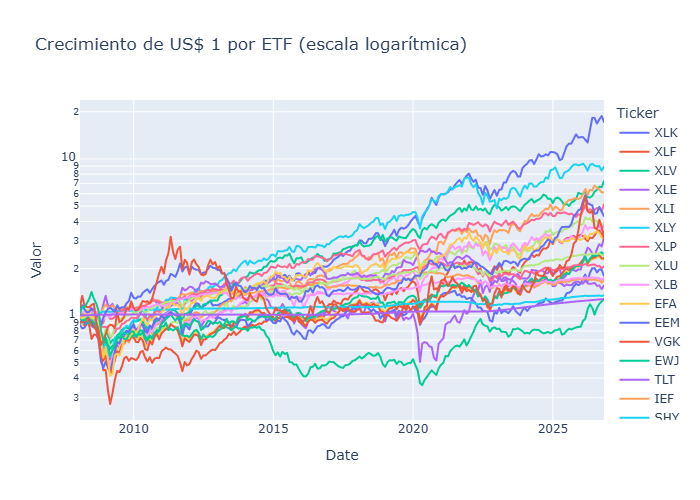

In [5]:
summary = pd.DataFrame({
    "Nombre": [NAMES[t] for t in tickers],
    "Clase": [UNIVERSE[t] for t in tickers],
    "Retorno anual medio": (1 + rets.mean()) ** 12 - 1,
    "Volatilidad anual": rets.std() * np.sqrt(12),
    "Peor mes": rets.min(),
    "Mejor mes": rets.max(),
}, index=tickers)
display(summary.style.format({"Retorno anual medio": "{:.1%}", "Volatilidad anual": "{:.1%}",
                              "Peor mes": "{:.1%}", "Mejor mes": "{:.1%}"}))

cum = (1 + rets).cumprod()
px.line(cum, title="Crecimiento de US$ 1 por ETF (escala logarítmica)", log_y=True,
        labels={"value": "Valor", "date": "Fecha", "variable": "ETF"}).show()

## 2. Modelo de Powell

Seguimos la notación de Powell con un solo cambio: la riqueza se llama $W_t$, así que la información exógena (que Powell llama $W_{t+1}$) aquí es $\hat R_{t+1}$.

### Tiempo
$t = 0, 1, \dots, T$ con $T = 120$ meses (10 años). La decisión $x_t$ se toma **al inicio del mes $t$**. Durante el mes llegan los retornos $\hat R_{t+1}$. En $t=0$ el cliente tiene todo su dinero sin invertir.

### 1. Variables de estado $S_t$

| Símbolo | Significado | Unidades |
|---|---|---|
| $W_t$ | Riqueza antes de operar | USD |
| $w_t \in \mathbb{R}^N$ | Pesos antes de operar, después de la deriva del mes anterior ($w_0 = 0$) | fracción de $W_t$ |
| $P_t = \max_{s \le t} W_s$ | Máximo de riqueza hasta la fecha (para medir caídas) | USD |
| $H_t \in \mathbb{R}^{12 \times N}$ | Retornos de los últimos 12 meses por activo (historia real antes de $t=0$, simulados después) | fracción / mes |
| $B_t$ | Memoria propia de cada política (ver abajo) | — |

La memoria $B_t$ depende de la política:
- **Venta por pánico:** el modo $m_t \in \{\text{invertido}, \text{en efectivo}\}$, el pico de referencia $\hat P_t$ (USD) y el mínimo $M_t$ desde que vendió (USD).
- **Persecución de rendimiento:** los pesos objetivo inclinados hacia los ganadores (fracción).
- **CFA:** los pesos objetivo vigentes $w^*_t$ y la ventana de retornos que usa para estimar (la historia real más los meses ya simulados).

Los parámetros del cliente $(\lambda, \alpha, \beta, W_{\text{ref}})$ son estáticos: entran al objetivo, pero no cambian con el tiempo.

### 2. Variables de decisión $x_t$
$x_{t,i}$ es el monto operado en el activo $i$ (USD; compras $>0$, ventas $<0$). Es equivalente a elegir los pesos después de operar $w_t^+$:

$$x_{t,i} = W_t\,(w^+_{t,i} - w_{t,i}), \qquad \sum_i w^+_{t,i} = 1, \qquad w^+_{t,i} \ge 0 .$$

No hay posiciones cortas ni apalancamiento. La decisión la toma una política $X^\pi(S_t \mid \theta)$.

**Qué se conoce al decidir:** todo $S_t$, es decir la riqueza, los pesos, el máximo y los retornos hasta el cierre del mes $t-1$, además de la historia real anterior a $t=0$. **No** se conoce $\hat R_{t+1}$.

### 3. Información exógena $\hat R_{t+1}$
$\hat R_{t+1} \in \mathbb{R}^N$ son los retornos simples del mes $t+1$ para cada activo (fracción). Los sorteamos con un **bootstrap circular por bloques** de 3 a 6 meses sobre la historia 2008–2026: cada mes sorteado es una fila histórica completa, con todos los activos de ese mes juntos, así que se conservan las correlaciones entre activos y parte de la autocorrelación (rachas, crisis).

### 4. Función de transición $S_{t+1} = S^M(S_t, x_t, \hat R_{t+1})$
Con un costo de transacción de $c = 0.001$ (10 pb) sobre el valor operado:

$$C_t = c \sum_i |x_{t,i}| = c\, W_t \sum_i |w^+_{t,i} - w_{t,i}|$$

$$W_{t+1} = (W_t - C_t)\,\bigl(1 + w_t^{+\top} \hat R_{t+1}\bigr)$$

$$w_{t+1,i} = \frac{w^+_{t,i}\,(1 + \hat R_{t+1,i})}{1 + w_t^{+\top} \hat R_{t+1}}$$

$$P_{t+1} = \max(P_t, W_{t+1}), \qquad H_{t+1} = \bigl(H_t[2{:}12],\ \hat R_{t+1}\bigr)$$

La memoria $B_{t+1}$ se actualiza según la regla de cada política.

### 5. Función objetivo
Buscamos la política que maximiza el valor esperado de prospect theory de la riqueza final, medido contra un punto de referencia:

$$\max_{\pi}\ \mathbb{E}\left[ v\!\left( \frac{W^\pi_T - W_{\text{ref}}}{W_0} \right) \right], \qquad
v(x) = \begin{cases} x^\alpha & x \ge 0 \\ -\lambda\,(-x)^\beta & x < 0 \end{cases}$$

Por defecto $W_{\text{ref}} = W_0$ (no perder dinero). Como alternativa, $W_{\text{ref}} = W_0 (1+g)^{10}$ (una meta de crecimiento anual $g$). $x$ no tiene unidades: es la ganancia relativa a la riqueza inicial. Por eso el cuestionario plantea las loterías en % del portafolio, y así $\alpha$, $\beta$ y $\lambda$ quedan en las mismas unidades que $x$. No hay recompensas intermedias: los costos entran a través de la transición. Además reportamos la media y los percentiles de $W_T$, la caída máxima y los costos pagados.

### Políticas

| Política | Clase | Regla | Parámetros ajustables |
|---|---|---|---|
| Comprar y mantener | Baseline | Compra el portafolio de la Parte 2 en $t=0$ y no vuelve a operar | — |
| Rebalanceo por bandas | **PFA** | Si $\max_i \lvert w_{t,i} - w^*_i\rvert > b$, vuelve a $w^*$; si no, no opera | $b$ |
| Re-optimización anual | **CFA** | Cada 12 meses resuelve el MILP con límite $c(\lambda)\,\theta$ sobre los últimos $N$ meses y lleva el portafolio a la solución | $\theta$, $N$ |
| Venta por pánico | Conductual | Encima de la PFA: si la caída llega a $d$, vende una fracción $\varphi$ a efectivo; vuelve tras un rebote $r$ desde el mínimo | $d, r, \varphi$ (del cuestionario) |
| Persecución de rendimiento | Conductual | Encima de la PFA: cada $f$ meses, objetivo $= (1-\kappa)\,w^* + \kappa \cdot$ (3 mejores activos a 12 meses) | $\kappa, f$ (del cuestionario) |
| Tú tal como eres | Conductual | La PFA con los sesgos que detectó el cuestionario | — |

### Justificación de los métodos
- **MILP media-CVaR en vez de un MIQP media-varianza.** Es lineal, así que se resuelve en milisegundos, y eso importa porque la CFA lo vuelve a resolver miles de veces dentro del simulador. El CVaR mide la cola de pérdidas, que es justo lo que le duele a un cliente con aversión a pérdidas. Y el límite $c(\lambda)$ se explica fácil: "a mayor aversión a pérdidas, menor pérdida tolerada en un mal mes".
- **Bootstrap por bloques.** No supone normalidad; conserva las colas gruesas, las correlaciones entre activos y la dependencia de corto plazo (de 3 a 6 meses).
- **PFA de bandas.** Es la regla más usada en la práctica, tiene un solo parámetro y es fácil de seguir para el cliente.
- **CFA de re-optimización.** Usa el modelo de la Parte 2 como aproximación determinista que se reajusta con la información nueva. El factor $\theta$ y la ventana $N$ corrigen que el MILP ignora el futuro.
- **Por qué no VFA ni DLA.** El estado es continuo y de alta dimensión (24 pesos más la historia reciente). Aproximar una función de valor sobre ese estado (VFA), o resolver una anticipación estocástica en cada mes de cada escenario (DLA), no es viable en una semana ni es fácil de explicar al cliente.

## 3. Parte 1: cuestionario y perfil del cliente

Son 11 preguntas, todas expresadas en % del portafolio:

- **λ (3 preguntas).** Lotería 50/50: "pierdes L% o ganas G%", con L = 5%, 10% y 20%. El cliente elige la **menor G con la que aceptaría**. Tomamos $\lambda = \text{mediana}(G/L)$, acotada a $[1, 5]$; la respuesta "no aceptaría" cuenta como 5. Aparte reportamos el λ corregido por curvatura, $G^\alpha / L^\beta$.
- **α (2 preguntas).** Equivalente cierto (CE) de "50%: ganas G; 50%: nada", con G = 10% y 30%. Si $CE^\alpha = \tfrac12 G^\alpha$, entonces $\alpha = \ln(0.5)/\ln(CE/G)$. Promediamos las dos y acotamos a $[0.2, 1]$.
- **β (2 preguntas).** La mayor pérdida segura que el cliente aceptaría para evitar "50%: pierdes L; 50%: nada". Por el mismo razonamiento, $\beta = \ln(0.5)/\ln(CE/L)$.
- **Sesgos (4 preguntas).** Cada respuesta fija los parámetros de las políticas conductuales:

| Pregunta | Respuesta → parámetro |
|---|---|
| B1: "Tu portafolio cayó 20% en tres meses" | Vendo todo → pánico con $d=10\%$, $\varphi=1$ · Vendo una parte → pánico con $d=20\%$, $\varphi=0.5$ · No hago nada / compro más → sin pánico |
| B2: "¿Cuándo volverías a invertir?" | Rebote de 5% → $r=5\%$ · de 15% → $r=15\%$ · cuando recupere todo → $r=25\%$ |
| B3: "Un ETF subió 40% y tu portafolio 5%" | Muevo buena parte → $\kappa=0.5$ · Un poco → $\kappa=0.25$ · Nada → sin persecución |
| B4: "¿Cada cuánto revisas tu portafolio?" | Mensual → $f=1$ · Trimestral → $f=3$ · Anual → $f=12$ |

No usamos ponderación de probabilidades: el enunciado solo pide la función de valor $v(x)$.

In [6]:
%%writefile core/profile.py
"""Parte 1: cuestionario y estimación de los parámetros de prospect theory."""
from dataclasses import dataclass, asdict
import math
import numpy as np

LAM_RATIOS = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
LAM_MIN, LAM_MAX = 1.0, 5.0
CURV_MIN, CURV_MAX = 0.2, 1.0

LAMBDA_QUESTIONS = [{"id": f"lam_{L}", "loss": L} for L in (5, 10, 20)]
ALPHA_QUESTIONS = [{"id": f"alpha_{G}", "stake": G} for G in (10, 30)]
BETA_QUESTIONS = [{"id": f"beta_{L}", "stake": L} for L in (10, 30)]

BIAS_QUESTIONS = [
    {"id": "b1", "text": "Tu portafolio cayó 20% en los últimos tres meses. ¿Qué haces?",
     "options": ["Vendo todo y paso a efectivo", "Vendo una parte", "No hago nada", "Aprovecho y compro más"]},
    {"id": "b2", "text": "Si hubieras vendido, ¿cuándo volverías a invertir?",
     "options": ["Cuando el mercado rebote 5% desde el mínimo", "Cuando rebote 15% desde el mínimo",
                 "Cuando recupere todo lo perdido"]},
    {"id": "b3", "text": "Un ETF subió 40% en el último año y tu portafolio solo 5%. ¿Qué haces?",
     "options": ["Muevo buena parte de mi dinero a ese ETF", "Muevo un poco", "Nada, sigo mi plan"]},
    {"id": "b4", "text": "¿Cada cuánto revisas y ajustas tu portafolio?",
     "options": ["Cada mes", "Cada trimestre", "Una vez al año"]},
]
B1_MAP = [(True, 0.10, 1.0), (True, 0.20, 0.5), (False, None, None), (False, None, None)]  # (pánico, d, φ)
B2_MAP = [0.05, 0.15, 0.25]   # r
B3_MAP = [0.50, 0.25, 0.0]    # κ
B4_MAP = [1, 3, 12]           # f (meses)

DEFAULT_ANSWERS = {
    "lam_5": 2.0, "lam_10": 2.0, "lam_20": 2.5,
    "alpha_10": 4.0, "alpha_30": 12.0, "beta_10": 4.0, "beta_30": 12.0,
    "b1": 2, "b2": 1, "b3": 2, "b4": 1,
}


def lambda_text(L):
    return (f"Lanzamos una moneda. Si sale cara pierdes el {L}% de tu portafolio; si sale sello ganas G%. "
            f"¿Cuál es la ganancia G más pequeña con la que aceptarías jugar?")


def lambda_options(L):
    """Lista de (etiqueta, razón G/L); None = no aceptaría."""
    return [(f"{L * r:g}%", r) for r in LAM_RATIOS] + [("No aceptaría con ninguna de estas", None)]


def alpha_text(G):
    return (f"Puedes quedarte con una apuesta (50%: ganas el {G}% de tu portafolio; 50%: no ganas nada) "
            f"o recibir una ganancia segura. ¿Cuál es la ganancia segura mínima (en %) por la que cambiarías la apuesta?")


def beta_text(L):
    return (f"Debes elegir entre una apuesta (50%: pierdes el {L}% de tu portafolio; 50%: no pierdes nada) "
            f"o una pérdida segura. ¿Cuál es la pérdida segura máxima (en %) que aceptarías para evitar la apuesta?")


@dataclass(frozen=True)
class Profile:
    lam: float = 2.25          # aversión a pérdidas λ
    alpha: float = 0.88        # curvatura en ganancias α
    beta: float = 0.88         # curvatura en pérdidas β
    lam_curv: float = float("nan")   # λ corregido por curvatura (solo informativo)
    panic: bool = False        # ¿vende en pánico?
    d: float = 0.20            # caída que dispara la venta
    r: float = 0.15            # rebote desde el mínimo para volver a invertir
    phi: float = 1.0           # fracción que vende
    chase: bool = False        # ¿persigue rendimientos?
    kappa: float = 0.25        # fracción que mueve a los ganadores
    f: int = 3                 # cada cuántos meses persigue
    top_k: int = 3             # número de ganadores

    def as_dict(self):
        return asdict(self)


def curvature_from_ce(ce, stake):
    """α (o β) a partir del equivalente cierto de una lotería 50/50 entre `stake` y 0."""
    ratio = min(max(float(ce) / float(stake), 0.01), 0.99)
    return float(np.clip(math.log(0.5) / math.log(ratio), CURV_MIN, CURV_MAX))


def estimate_profile(answers=None):
    """Respuestas del cuestionario → Profile. Las respuestas que falten toman su valor por defecto."""
    a = {**DEFAULT_ANSWERS, **(answers or {})}
    ratios = [LAM_MAX if a[q["id"]] is None else float(a[q["id"]]) for q in LAMBDA_QUESTIONS]
    lam = float(np.clip(np.median(ratios), LAM_MIN, LAM_MAX))
    alpha = float(np.mean([curvature_from_ce(a[q["id"]], q["stake"]) for q in ALPHA_QUESTIONS]))
    beta = float(np.mean([curvature_from_ce(a[q["id"]], q["stake"]) for q in BETA_QUESTIONS]))
    lam_curv = float(np.median([((r * q["loss"] / 100) ** alpha) / ((q["loss"] / 100) ** beta)
                                for r, q in zip(ratios, LAMBDA_QUESTIONS)]))
    panic, d, phi = B1_MAP[int(a["b1"])]
    kappa = B3_MAP[int(a["b3"])]
    base = Profile()
    return Profile(
        lam=lam, alpha=alpha, beta=beta, lam_curv=lam_curv,
        panic=panic, d=d if panic else base.d, r=B2_MAP[int(a["b2"])], phi=phi if panic else base.phi,
        chase=kappa > 0, kappa=kappa if kappa > 0 else base.kappa, f=B4_MAP[int(a["b4"])],
    )


def describe_profile(p):
    """Frases en lenguaje simple para el cliente."""
    level = "baja" if p.lam < 1.5 else ("moderada" if p.lam < 2.5 else "alta")
    out = [f"**Aversión a pérdidas {level} (λ = {p.lam:.2f}).** Una pérdida te pesa {p.lam:.1f} veces "
           f"lo que te alegra una ganancia del mismo tamaño."]
    if p.alpha < 0.95:
        out.append(f"**Con ganancias prefieres asegurar (α = {p.alpha:.2f}).** Cambiarías una apuesta por una "
                   f"ganancia segura menor que su valor esperado.")
    else:
        out.append(f"**Con ganancias eres casi neutral al riesgo (α = {p.alpha:.2f}).**")
    if p.beta < 0.95:
        out.append(f"**Con pérdidas tiendes a arriesgar (β = {p.beta:.2f}).** Prefieres apostar antes que "
                   f"aceptar una pérdida segura.")
    else:
        out.append(f"**Con pérdidas eres casi neutral al riesgo (β = {p.beta:.2f}).**")
    if p.panic:
        out.append(f"**Sesgo detectado: venta por pánico.** Venderías el {p.phi:.0%} de tu portafolio tras una "
                   f"caída de {p.d:.0%} y volverías a invertir tras un rebote de {p.r:.0%}.")
    if p.chase:
        each = "cada mes" if p.f == 1 else f"cada {p.f} meses"
        out.append(f"**Sesgo detectado: persecución de rendimiento.** {each.capitalize()} moverías el "
                   f"{p.kappa:.0%} de tu dinero hacia los activos que más subieron en el último año.")
    if not (p.panic or p.chase):
        out.append("**No detectamos sesgos de comportamiento** en tus respuestas.")
    return out


def pt_value(x, alpha, beta, lam):
    """Función de valor de prospect theory: x^α si x ≥ 0; −λ(−x)^β si x < 0."""
    x = np.asarray(x, dtype=float)
    ax = np.abs(x)
    return np.where(x >= 0, ax ** alpha, -lam * ax ** beta)

Overwriting core/profile.py


In [7]:
from core.profile import (Profile, estimate_profile, describe_profile, pt_value, DEFAULT_ANSWERS,
                          B1_MAP, B2_MAP, B3_MAP, B4_MAP)

# Ejemplo: un cliente que responde las opciones por defecto
example = estimate_profile(DEFAULT_ANSWERS)
print(example)
display(Markdown("\n".join(f"- {s}" for s in describe_profile(example))))

Profile(lam=2.0, alpha=0.7564707973660301, beta=0.7564707973660301, lam_curv=1.6893529746156712, panic=False, d=0.2, r=0.15, phi=1.0, chase=False, kappa=0.25, f=3, top_k=3)


- **Aversión a pérdidas moderada (λ = 2.00).** Una pérdida te pesa 2.0 veces lo que te alegra una ganancia del mismo tamaño.
- **Con ganancias prefieres asegurar (α = 0.76).** Cambiarías una apuesta por una ganancia segura menor que su valor esperado.
- **Con pérdidas tiendes a arriesgar (β = 0.76).** Prefieres apostar antes que aceptar una pérdida segura.
- **No detectamos sesgos de comportamiento** en tus respuestas.

In [8]:
# Pruebas del perfil (comportamiento observable de estimate_profile y pt_value)
neutral = {"lam_5": 1.0, "lam_10": 1.0, "lam_20": 1.0, "alpha_10": 5.0, "alpha_30": 15.0,
           "beta_10": 5.0, "beta_30": 15.0, "b1": 2, "b2": 1, "b3": 2, "b4": 1}
p = estimate_profile(neutral)
assert abs(p.alpha - 1) < 1e-9 and abs(p.beta - 1) < 1e-9 and p.lam == 1.0, "neutral al riesgo → α = β = λ = 1"
assert not p.panic and not p.chase

extreme = {**neutral, "lam_5": None, "lam_10": None, "lam_20": None, "alpha_10": 0.0, "alpha_30": 0.0}
p = estimate_profile(extreme)
assert p.lam == 5.0 and p.alpha == 0.2, "'nunca' → λ = 5; CE = 0 → α en su cota inferior"

for i, (panic, d, phi) in enumerate(B1_MAP):
    p = estimate_profile({**neutral, "b1": i})
    assert p.panic == panic and (not panic or (p.d == d and p.phi == phi))
for i, r in enumerate(B2_MAP):
    assert estimate_profile({**neutral, "b2": i}).r == r
for i, k in enumerate(B3_MAP):
    p = estimate_profile({**neutral, "b3": i})
    assert p.chase == (k > 0) and (k == 0 or p.kappa == k)
for i, f in enumerate(B4_MAP):
    assert estimate_profile({**neutral, "b4": i}).f == f

assert np.isclose(pt_value(0.10, 1, 1, 2), 0.10) and np.isclose(pt_value(-0.10, 1, 1, 2), -0.20)
assert np.isclose(pt_value(0.25, 0.5, 1, 2), 0.5)
print("✓ Perfil: todas las pruebas pasan")

✓ Perfil: todas las pruebas pasan


### Cliente de referencia

Para ajustar las políticas y para la evaluación del informe usamos un **cliente de referencia** con los parámetros clásicos de Tversky y Kahneman (λ = 2.25, α = β = 0.88). Le asignamos además los dos sesgos con sus parámetros típicos (pánico con d = 20%, r = 15%, φ = 1; persecución con κ = 0.25 cada 3 meses), para que la evaluación muestre el costo de ambos. En el dashboard, cada cliente obtiene sus propios parámetros.

In [9]:
REF = Profile(panic=True, chase=True)
W0 = 100_000.0     # riqueza inicial (USD)
COST = 0.001       # 10 pb sobre el valor operado
print(REF)

Profile(lam=2.25, alpha=0.88, beta=0.88, lam_curv=nan, panic=True, d=0.2, r=0.15, phi=1.0, chase=True, kappa=0.25, f=3, top_k=3)


## 4. Parte 2: portafolio MILP media-CVaR (Gurobi)

**Variables.** $w_i \ge 0$ es el peso del activo $i$; $z_i \in \{0,1\}$ indica si el activo entra; $\zeta$ es el VaR; $u_s \ge 0$ es el exceso de pérdida en el mes histórico $s$.

$$\max_{w,z,\zeta,u}\ \bar r^\top w$$

sujeto a:

$$\sum_i w_i = 1,\qquad \sum_i z_i \le K,\qquad l\,z_i \le w_i \le u\,z_i,\qquad \sum_{i \in c} w_i \le \bar w_c\ \ \forall c$$

$$u_s \ge -r_s^\top w - \zeta,\qquad \zeta + \frac{1}{(1-\beta_{\text{CVaR}})\,S} \sum_s u_s \le c(\lambda)$$

La última restricción es la linealización de Rockafellar–Uryasev del CVaR al 95%, calculada sobre los $S$ meses históricos.

**Vínculo con el perfil.** El límite de pérdida en meses malos baja en línea recta con la aversión a pérdidas:

$$c(\lambda) = \theta\,\Bigl[c_{\max} - (c_{\max} - c_{\min})\,\tfrac{\lambda - 1}{4}\Bigr], \qquad c_{\max} = 10\%,\ c_{\min} = 2\%\ (\text{CVaR mensual}),\ \lambda \in [1,5].$$

En la Parte 2, $\theta = 1$; la CFA ajusta $\theta$. Valores por defecto: $K = 8$, $l = 5\%$, $u = 35\%$ y tope por clase de $50\%$, todos modificables en el dashboard. Si el límite de CVaR resulta infactible, el modelo usa el portafolio de mínimo CVaR y lo informa.

In [10]:
%%writefile core/portfolio.py
"""Parte 2: portafolio media-CVaR (MILP, linealización de Rockafellar–Uryasev) con Gurobi."""
from dataclasses import dataclass
import numpy as np
import pandas as pd

C_MAX, C_MIN = 0.10, 0.02
_ENV = None


@dataclass(frozen=True)
class Constraints:
    K: int = 8                 # máximo de activos
    l: float = 0.05            # posición mínima si el activo entra
    u: float = 0.35            # posición máxima
    class_cap: float = 0.50    # tope por clase de activo ("sector")
    beta: float = 0.95         # nivel del CVaR


@dataclass
class Portfolio:
    weights: pd.Series         # pesos por ticker (fracción)
    mean: float                # retorno mensual esperado (histórico)
    cvar: float                # CVaR mensual histórico (pérdida, fracción)
    cvar_limit: float          # límite c(λ)·θ usado
    status: str

    def table(self, wealth=None):
        from .data import UNIVERSE, NAMES
        w = self.weights[self.weights > 0].sort_values(ascending=False)
        out = pd.DataFrame({"Nombre": [NAMES.get(t, t) for t in w.index],
                            "Clase": [UNIVERSE.get(t, "") for t in w.index],
                            "Peso": w.values}, index=w.index)
        if wealth is not None:
            out["Monto a invertir (US$)"] = w.values * wealth
        return out


def cvar_limit(lam, theta=1.0, c_max=C_MAX, c_min=C_MIN):
    """Límite de CVaR mensual: baja en línea recta de c_max (λ = 1) a c_min (λ = 5)."""
    lam = float(np.clip(lam, 1.0, 5.0))
    return float(theta * (c_max - (c_max - c_min) * (lam - 1.0) / 4.0))


def hist_cvar(port_returns, beta=0.95):
    """CVaR histórico de la pérdida (mínimo de la función de Rockafellar–Uryasev)."""
    losses = -np.asarray(port_returns, dtype=float)
    var = np.quantile(losses, beta, method="inverted_cdf")
    return float(var + np.maximum(losses - var, 0.0).sum() / ((1.0 - beta) * losses.size))


def class_matrix(tickers, classes):
    """Matriz A (clases × activos) con A[c, i] = 1 si el activo i pertenece a la clase c."""
    names = list(dict.fromkeys(classes[t] for t in tickers))
    A = np.array([[1.0 if classes[t] == c else 0.0 for t in tickers] for c in names])
    return A, names


def _env():
    global _ENV
    if _ENV is None:
        import gurobipy as gp
        _ENV = gp.Env(empty=True)
        _ENV.setParam("OutputFlag", 0)
        _ENV.start()
    return _ENV


def solve_cvar_milp(R, A, cons, limit, time_limit=10.0):
    """Resuelve el MILP media-CVaR sobre los escenarios R (S × N). Devuelve (pesos, estado)."""
    import gurobipy as gp
    from gurobipy import GRB

    R = np.asarray(R, dtype=float)
    A = np.asarray(A, dtype=float)
    S, N = R.shape
    if cons.K * cons.u < 1.0 - 1e-9:
        raise ValueError("Infactible: K · u < 1 (no se puede invertir el 100%).")
    mu = R.mean(axis=0)
    coef = np.full(S, 1.0 / ((1.0 - cons.beta) * S))

    def run(with_limit):
        m = gp.Model(env=_env())
        m.Params.TimeLimit = time_limit
        m.Params.MIPGap = 1e-6
        w = m.addMVar(N, lb=0.0, ub=1.0, name="w")
        z = m.addMVar(N, vtype=GRB.BINARY, name="z")
        zeta = m.addMVar(1, lb=-GRB.INFINITY, name="zeta")
        exc = m.addMVar(S, lb=0.0, name="u")
        m.addConstr(w.sum() == 1.0)
        m.addConstr(z.sum() <= cons.K)
        m.addConstr(w - cons.l * z >= 0)
        m.addConstr(w - cons.u * z <= 0)
        m.addConstr(A @ w <= cons.class_cap)
        m.addConstr(R @ w + exc + np.ones((S, 1)) @ zeta >= 0)      # u_s ≥ −r_s·w − ζ
        cvar = zeta[0] + coef @ exc
        if with_limit:
            m.addConstr(cvar <= limit)
            m.setObjective(mu @ w, GRB.MAXIMIZE)
        else:
            m.setObjective(cvar, GRB.MINIMIZE)
        m.optimize()
        x = w.X.copy() if m.SolCount > 0 else None
        opt = m.Status == GRB.OPTIMAL
        m.dispose()
        return x, opt

    x, opt = run(True)
    if x is not None:
        status = "óptimo" if opt else "factible (límite de tiempo)"
    else:
        x, _ = run(False)
        if x is None:
            raise RuntimeError("El MILP no encontró solución: revisa K, l, u y el tope por clase.")
        status = "límite de CVaR infactible: se usó el portafolio de mínimo CVaR"
    x = np.where(x < 1e-7, 0.0, x)
    return x / x.sum(), status


def build_portfolio(profile, returns, cons=Constraints(), theta=1.0, classes=None):
    """Perfil (o λ) + retornos históricos (DataFrame) + restricciones → Portfolio."""
    from .data import UNIVERSE
    classes = classes or UNIVERSE
    lam = getattr(profile, "lam", profile)
    tickers = list(returns.columns)
    A, _ = class_matrix(tickers, classes)
    R = returns.to_numpy(dtype=float)
    limit = cvar_limit(lam, theta)
    w, status = solve_cvar_milp(R, A, cons, limit)
    pr = R @ w
    return Portfolio(pd.Series(w, index=tickers), float(pr.mean()), hist_cvar(pr, cons.beta), limit, status)

Overwriting core/portfolio.py


In [11]:
from core.portfolio import Constraints, build_portfolio, cvar_limit, hist_cvar, class_matrix

CONS = Constraints()
A, class_names = class_matrix(tickers, UNIVERSE)

port_ref = build_portfolio(REF, rets, CONS)
w_star = port_ref.weights.to_numpy()
print(f"Estado: {port_ref.status}")
print(f"Retorno esperado anual: {(1 + port_ref.mean) ** 12 - 1:.2%}   "
      f"CVaR95 mensual: {port_ref.cvar:.2%}  (límite {port_ref.cvar_limit:.2%})")
display(port_ref.table(W0).style.format({"Peso": "{:.1%}", "Monto a invertir (US$)": "{:,.0f}"}))

Estado: óptimo
Retorno esperado anual: 13.42%   CVaR95 mensual: 7.50%  (límite 7.50%)


,Nombre,Clase,Peso,Monto a invertir (US$)
XLK,Tecnología EE.UU.,Acciones EE.UU.,35.0%,"35,000"
GLD,Oro,Activos reales,35.0%,"35,000"
XLV,Salud EE.UU.,Acciones EE.UU.,10.0%,"10,000"
SLV,Plata,Activos reales,8.7%,"8,683"
VNQ,Bienes raíces (REITs),Activos reales,6.3%,"6,317"
XLY,Consumo discrecional EE.UU.,Acciones EE.UU.,5.0%,"5,000"


In [12]:
# Pruebas del MILP: restricciones y vínculo con λ
tol = 1e-6
ports = {lam: build_portfolio(lam, rets, CONS) for lam in (1.0, 2.25, 4.0, 5.0)}
for lam, pt in ports.items():
    w = pt.weights.to_numpy()
    held = w > 0
    assert abs(w.sum() - 1) < tol and (w >= -tol).all()
    assert held.sum() <= CONS.K
    assert (w[held] >= CONS.l - tol).all() and (w <= CONS.u + tol).all()
    assert (A @ w <= CONS.class_cap + tol).all()
    if pt.status == "óptimo":
        assert pt.cvar <= pt.cvar_limit + 1e-5, f"CVaR ex post sobre el límite con λ={lam}"
means = [ports[l].mean for l in sorted(ports)]
assert all(a >= b - 1e-6 for a, b in zip(means, means[1:])), "al subir λ la media no puede subir"

frontier = pd.DataFrame({
    "λ": list(ports),
    "Límite CVaR": [p.cvar_limit for p in ports.values()],
    "CVaR": [p.cvar for p in ports.values()],
    "Retorno anual": [(1 + p.mean) ** 12 - 1 for p in ports.values()],
    "Activos": [int((p.weights > 0).sum()) for p in ports.values()],
    "Estado": [p.status for p in ports.values()],
}).set_index("λ")
display(frontier.style.format({"Límite CVaR": "{:.1%}", "CVaR": "{:.2%}", "Retorno anual": "{:.2%}"}))
print("✓ MILP: todas las pruebas pasan")

,Límite CVaR,CVaR,Retorno anual,Activos,Estado
λ,,,,,
1.000000,10.0%,10.00%,14.21%,4,óptimo
2.250000,7.5%,7.50%,13.42%,6,óptimo
4.000000,4.0%,4.00%,9.00%,6,óptimo
5.000000,2.0%,2.00%,5.16%,5,óptimo


✓ MILP: todas las pruebas pasan


## 5. Escenarios: bootstrap circular por bloques

Cada escenario son 120 meses armados con bloques de meses históricos consecutivos. La longitud de cada bloque se sortea uniformemente entre 3 y 6 meses, y el bloque empieza en un mes al azar (circular: si pasa del último mes, sigue por el primero). Cada mes sorteado es **una fila histórica completa**, con los 24 activos de ese mes.

**Números aleatorios comunes.** Por cada semilla generamos un solo tensor (escenarios × meses × activos), y **todas** las políticas se simulan sobre ese mismo tensor. Así, la diferencia entre dos políticas mide el efecto de la política y no la suerte de cada una.

| Uso | Semilla | Escenarios |
|---|---|---|
| Ajuste de parámetros | 2026 | 300 (150 para la CFA) |
| Evaluación final | 7777 | 1000 |
| Pruebas unitarias | 123 | 50 |

In [13]:
%%writefile core/scenarios.py
"""Escenarios: bootstrap circular por bloques de 3 a 6 meses (filas históricas completas)."""
from dataclasses import dataclass
import numpy as np

TUNE_SEED = 2026
EVAL_SEED = 7777
HORIZON = 120


@dataclass
class Scenarios:
    returns: np.ndarray        # (S, H, N) retornos mensuales simulados
    index: np.ndarray          # (S, H) fila histórica usada en cada mes
    block_lengths: list        # por escenario: longitudes de bloque (la última puede venir truncada)
    seed: int

    @property
    def n(self):
        return self.returns.shape[0]

    def subset(self, n):
        return Scenarios(self.returns[:n], self.index[:n], self.block_lengths[:n], self.seed)


def block_bootstrap(hist, n_scen, horizon=HORIZON, seed=0, min_block=3, max_block=6):
    hist = np.asarray(hist, dtype=float)
    T = hist.shape[0]
    rng = np.random.default_rng(seed)
    idx = np.empty((n_scen, horizon), dtype=np.int64)
    lengths = []
    for s in range(n_scen):
        t, ls = 0, []
        while t < horizon:
            L = int(rng.integers(min_block, max_block + 1))
            start = int(rng.integers(0, T))
            take = min(L, horizon - t)
            idx[s, t:t + take] = (start + np.arange(take)) % T
            ls.append(take)
            t += take
        lengths.append(np.array(ls))
    return Scenarios(hist[idx], idx, lengths, seed)

Overwriting core/scenarios.py


In [14]:
from core.scenarios import block_bootstrap, Scenarios, TUNE_SEED, EVAL_SEED, HORIZON

# Pruebas del bootstrap
sa, sb, sc_ = (block_bootstrap(hist, 20, seed=s) for s in (1, 1, 2))
assert np.array_equal(sa.returns, sb.returns), "misma semilla → mismo tensor"
assert not np.array_equal(sa.returns, sc_.returns), "otra semilla → otro tensor"
assert np.array_equal(sa.returns, hist[sa.index]), "cada mes es una fila histórica completa"
for s in range(sa.n):
    ls = sa.block_lengths[s]
    assert ls.sum() == HORIZON
    assert ((ls[:-1] >= 3) & (ls[:-1] <= 6)).all() and 1 <= ls[-1] <= 6
    pos = 0
    for L in ls:
        assert (np.diff(sa.index[s, pos:pos + L]) % T_HIST == 1).all(), "los bloques son meses consecutivos"
        pos += L
assert TUNE_SEED != EVAL_SEED
print("✓ Escenarios: todas las pruebas pasan")

✓ Escenarios: todas las pruebas pasan


## 6. Parte 3: simulador y políticas

Todas las políticas cumplen la misma interfaz: `decide(estado) → pesos después de operar` (una fila por escenario). El simulador está vectorizado: avanza los 1000 escenarios a la vez, mes a mes, aplicando la función de transición de la sección 2. Además valida en cada mes que los pesos sumen 1 y no sean negativos.

**Detalles de las políticas conductuales.**
- **Venta por pánico.** Mide la caída contra su propio pico de referencia. Al llegar a $d$, vende la fracción $\varphi$ de cada posición y la pasa a BIL. Mientras está fuera, no opera, y sigue el mínimo $M_t$ de su riqueza. Cuando $W_t \ge M_t(1+r)$, vuelve a los pesos objetivo y reinicia su pico de referencia. Sin ese reinicio volvería a vender al mes siguiente, porque la riqueza sigue lejos del máximo anterior.
- **Persecución de rendimiento.** Cada $f$ meses calcula el retorno acumulado de 12 meses de cada activo y lleva su objetivo a $(1-\kappa)\,w^* + \kappa \cdot$ (pesos iguales en los 3 mejores). Opera hasta ese objetivo y, entre revisiones, rebalancea por bandas alrededor de él.

In [15]:
%%writefile core/policies.py
"""Políticas: baseline, PFA (bandas), CFA (re-optimización anual) y conductuales."""
import numpy as np
from .portfolio import solve_cvar_milp, cvar_limit

BH = "Comprar y mantener"
PFA = "Rebalanceo por bandas"
CFA = "Re-optimización anual"
PANIC = "Venta por pánico"
CHASE = "Persecución de rendimiento"
CLIENT = "Tú tal como eres"


def _rows(target, S):
    t = np.asarray(target, dtype=float)
    if t.ndim == 1:
        t = np.broadcast_to(t, (S, t.size))
    return np.array(t, dtype=float, copy=True)


class Policy:
    name = "Política"
    klass = ""

    def params(self):
        return {}

    def reset(self, S, N):
        self.S, self.N = S, N

    def decide(self, st):
        raise NotImplementedError

    def target_weights(self):
        raise NotImplementedError


class BuyAndHold(Policy):
    """Baseline: compra el portafolio objetivo en t = 0 y no vuelve a operar."""
    klass = "Baseline"

    def __init__(self, target, name=BH):
        self.target0 = np.asarray(target, dtype=float)
        self.name = name

    def reset(self, S, N):
        super().reset(S, N)
        self.T = _rows(self.target0, S)

    def target_weights(self):
        return self.T

    def decide(self, st):
        return self.T.copy() if st.t == 0 else st.w


class BandRebalancing(Policy):
    """PFA: vuelve a los pesos objetivo cuando algún peso se aleja más de b."""
    klass = "PFA"

    def __init__(self, target, b, name=PFA):
        self.target0 = np.asarray(target, dtype=float)
        self.b = float(b)
        self.name = name

    def params(self):
        return {"b": self.b}

    def reset(self, S, N):
        super().reset(S, N)
        self.T = _rows(self.target0, S)

    def target_weights(self):
        return self.T

    def decide(self, st):
        if st.t == 0:
            return self.T.copy()
        out = st.w.copy()
        hit = np.abs(st.w - self.T).max(axis=1) > self.b
        out[hit] = self.T[hit]
        return out


class AnnualReoptimization(Policy):
    """CFA: cada `every` meses resuelve el MILP con límite c(λ)·θ sobre los últimos `window` meses."""
    klass = "CFA"
    _cache = {}

    def __init__(self, lam, theta, window, cons, A, hist, every=12, name=CFA):
        self.lam, self.theta, self.window = float(lam), float(theta), int(window)
        self.cons, self.A = cons, np.asarray(A, dtype=float)
        self.hist = np.asarray(hist, dtype=float)
        self.every, self.name = int(every), name
        self.limit = cvar_limit(self.lam, self.theta)
        self.n_solves = 0

    def params(self):
        return {"theta": self.theta, "window": self.window}

    def _solve(self, R):
        w, _ = solve_cvar_milp(R, self.A, self.cons, self.limit)
        self.n_solves += 1
        return w

    def reset(self, S, N):
        super().reset(S, N)
        key = (self.lam, self.theta, self.window, self.cons, self.hist.shape, float(self.hist.sum()))
        if key not in AnnualReoptimization._cache:      # en t = 0 todos los escenarios comparten la historia
            AnnualReoptimization._cache[key] = self._solve(self.hist[-self.window:])
        self.T = _rows(AnnualReoptimization._cache[key], S)

    def target_weights(self):
        return self.T

    def decide(self, st):
        if st.t == 0:
            return self.T.copy()
        if st.t % self.every == 0:
            for s in range(self.S):
                R = np.concatenate([self.hist, st.past[s]], axis=0)[-self.window:]
                self.T[s] = self._solve(R)
            return self.T.copy()
        return st.w


class PanicSelling(Policy):
    """Conductual: tras una caída d vende la fracción φ a efectivo; vuelve tras un rebote r desde el mínimo."""
    klass = "Conductual"

    def __init__(self, base, d, r, phi, cash_idx, name=PANIC):
        self.base, self.d, self.r, self.phi = base, float(d), float(r), float(phi)
        self.cash_idx, self.name = int(cash_idx), name

    def params(self):
        return {"d": self.d, "r": self.r, "phi": self.phi}

    def reset(self, S, N):
        super().reset(S, N)
        self.base.reset(S, N)
        self.in_cash = np.zeros(S, dtype=bool)
        self.ref_peak = np.full(S, -np.inf)
        self.trough = np.full(S, np.inf)
        self.e_cash = np.zeros(N)
        self.e_cash[self.cash_idx] = 1.0

    def target_weights(self):
        return self.base.target_weights()

    def decide(self, st):
        W = st.W
        inv = ~self.in_cash
        self.ref_peak[inv] = np.maximum(self.ref_peak[inv], W[inv])
        self.trough[self.in_cash] = np.minimum(self.trough[self.in_cash], W[self.in_cash])
        drawdown = 1.0 - W / self.ref_peak
        trigger = inv & (drawdown >= self.d)
        reenter = self.in_cash & (W >= self.trough * (1.0 + self.r))
        hold = self.in_cash & ~reenter

        out = self.base.decide(st)
        if trigger.any():
            out[trigger] = (1.0 - self.phi) * st.w[trigger] + self.phi * self.e_cash
        out[hold] = st.w[hold]
        if reenter.any():
            out[reenter] = self.base.target_weights()[reenter]

        self.in_cash[trigger] = True
        self.trough[trigger] = W[trigger]
        self.in_cash[reenter] = False
        self.ref_peak[reenter] = W[reenter]
        return out


class PerformanceChasing(Policy):
    """Conductual: cada f meses inclina el objetivo de la PFA hacia los top-k ganadores de 12 meses."""
    klass = "Conductual"

    def __init__(self, base, kappa, f, top_k=3, name=CHASE):
        self.base, self.kappa, self.f, self.top_k = base, float(kappa), int(f), int(top_k)
        self.name = name

    def params(self):
        return {"kappa": self.kappa, "f": self.f, "top_k": self.top_k}

    def reset(self, S, N):
        super().reset(S, N)
        self.base.reset(S, N)
        self.T0 = self.base.target_weights().copy()

    def target_weights(self):
        return self.base.target_weights()

    def decide(self, st):
        if st.t > 0 and st.t % self.f == 0 and self.kappa > 0:
            cum = np.prod(1.0 + st.recent, axis=1) - 1.0                  # (S, N) retorno a 12 meses
            top = np.argsort(-cum, axis=1)[:, :self.top_k]
            winners = np.zeros_like(cum)
            np.put_along_axis(winners, top, 1.0 / self.top_k, axis=1)
            self.base.T = (1.0 - self.kappa) * self.T0 + self.kappa * winners
            return self.base.T.copy()
        return self.base.decide(st)


def standard_policies(profile, w_star, b, cash_idx, cfa=None):
    """El conjunto de políticas que se compara en el notebook y en la app (mismos nombres y reglas)."""
    pols = [BuyAndHold(w_star), BandRebalancing(w_star, b)]
    if cfa is not None:
        pols.append(AnnualReoptimization(profile.lam, cfa["theta"], cfa["window"], cfa["cons"], cfa["A"], cfa["hist"]))
    pols.append(PanicSelling(BandRebalancing(w_star, b), profile.d, profile.r, profile.phi, cash_idx))
    pols.append(PerformanceChasing(BandRebalancing(w_star, b), profile.kappa, profile.f, profile.top_k))
    client = BandRebalancing(w_star, b, name=CLIENT)
    if profile.chase:
        client = PerformanceChasing(client, profile.kappa, profile.f, profile.top_k, name=CLIENT)
    if profile.panic:
        client = PanicSelling(client, profile.d, profile.r, profile.phi, cash_idx, name=CLIENT)
    client.klass = "Conductual (perfil)"
    pols.append(client)
    return pols

Overwriting core/policies.py


In [16]:
%%writefile core/simulator.py
"""Simulador vectorizado: aplica la función de transición del modelo de Powell mes a mes."""
from dataclasses import dataclass
import numpy as np


@dataclass
class State:
    t: int
    W: np.ndarray          # (S,) riqueza antes de operar, USD
    w: np.ndarray          # (S, N) pesos antes de operar (después de la deriva)
    peak: np.ndarray       # (S,) máximo de riqueza hasta la fecha, USD
    recent: np.ndarray     # (S, 12, N) retornos de los últimos 12 meses
    past: np.ndarray       # (S, t, N) retornos simulados hasta el mes t−1


@dataclass
class SimResult:
    name: str
    klass: str
    wealth: np.ndarray     # (S, H+1) riqueza, USD
    traded: np.ndarray     # (S,) valor total operado, USD
    costs: np.ndarray      # (S,) costos de transacción pagados, USD

    @property
    def terminal(self):
        return self.wealth[:, -1]

    @property
    def max_drawdown(self):
        peak = np.maximum.accumulate(self.wealth, axis=1)
        return (1.0 - self.wealth / peak).max(axis=1)


def simulate(policy, scenarios, hist, W0=100_000.0, cost=0.001):
    scen = getattr(scenarios, "returns", scenarios)
    S, H, N = scen.shape
    hist = np.asarray(hist, dtype=float)
    policy.reset(S, N)
    W = np.full(S, float(W0))
    w = np.zeros((S, N))                          # t = 0: todo el dinero sin invertir
    peak = W.copy()
    recent = np.broadcast_to(hist[-12:], (S, 12, N)).copy()
    path = np.empty((S, H + 1))
    path[:, 0] = W
    traded = np.zeros(S)
    costs = np.zeros(S)
    for t in range(H):
        st = State(t, W.copy(), w.copy(), peak.copy(), recent, scen[:, :t, :])
        x = np.asarray(policy.decide(st), dtype=float)
        if x.shape != (S, N) or (x < -1e-9).any() or not np.allclose(x.sum(axis=1), 1.0, atol=1e-6):
            raise ValueError(f"{policy.name}: pesos inválidos en t = {t}")
        tv = W * np.abs(x - w).sum(axis=1)       # valor operado
        c = cost * tv
        W = W - c
        R = scen[:, t, :]
        gross = 1.0 + (x * R).sum(axis=1)
        W = W * gross
        w = x * (1.0 + R) / gross[:, None]
        peak = np.maximum(peak, W)
        recent = np.concatenate([recent[:, 1:], R[:, None, :]], axis=1)
        traded += tv
        costs += c
        path[:, t + 1] = W
    return SimResult(policy.name, policy.klass, path, traded, costs)

Overwriting core/simulator.py


In [17]:
%%writefile core/evaluation.py
"""Evaluación: valor PT, intervalos de confianza, comparaciones pareadas, ajuste y recomendación."""
from statistics import NormalDist
import numpy as np
import pandas as pd
from .profile import pt_value
from .simulator import simulate
from .policies import BH, PFA, CFA, PANIC, CHASE, CLIENT


def usd(x):
    x = 0.0 if abs(x) < 0.5 else x          # evita "US$ -0"
    return "US$ " + f"{x:,.0f}".replace(",", ".")


def pt_scores(W_T, W0, W_ref, profile):
    x = (np.asarray(W_T, dtype=float) - W_ref) / W0
    return pt_value(x, profile.alpha, profile.beta, profile.lam)


def summarize(v, level=0.95, n_boot=2000, seed=0):
    """Media, desviación, percentiles e IC (normal y bootstrap percentil) de la media."""
    v = np.asarray(v, dtype=float)
    n = v.size
    m = float(v.mean())
    sd = float(v.std(ddof=1)) if n > 1 else 0.0
    z = NormalDist().inv_cdf(0.5 + level / 2)
    se = sd / np.sqrt(n)
    rng = np.random.default_rng(seed)
    boot = v[rng.integers(0, n, size=(n_boot, n))].mean(axis=1)
    lo, hi = np.quantile(boot, [(1 - level) / 2, (1 + level) / 2])
    p5, p50, p95 = np.percentile(v, [5, 50, 95])
    return {"mean": m, "std": sd, "p5": p5, "p50": p50, "p95": p95,
            "ci_low": m - z * se, "ci_high": m + z * se, "boot_low": lo, "boot_high": hi, "n": n}


def evaluate(policies, scenarios, hist, W0=100_000.0, cost=0.001):
    """Simula todas las políticas sobre el MISMO tensor de escenarios (números aleatorios comunes)."""
    names = [p.name for p in policies]
    assert len(set(names)) == len(names), "los nombres de las políticas deben ser únicos"
    return {p.name: simulate(p, scenarios, hist, W0=W0, cost=cost) for p in policies}


def results_table(results, profile, W0, W_ref=None):
    W_ref = W0 if W_ref is None else W_ref
    rows = []
    for name, res in results.items():
        pt = summarize(pt_scores(res.terminal, W0, W_ref, profile))
        wt = summarize(res.terminal)
        years = (res.wealth.shape[1] - 1) / 12
        rows.append({
            "Política": name, "Clase": res.klass,
            "Valor PT medio": pt["mean"], "Valor PT desv.": pt["std"],
            "Valor PT P5": pt["p5"], "Valor PT P95": pt["p95"],
            "IC95% PT (normal)": f"[{pt['ci_low']:.4f}, {pt['ci_high']:.4f}]",
            "IC95% PT (bootstrap)": f"[{pt['boot_low']:.4f}, {pt['boot_high']:.4f}]",
            "Riqueza final media": wt["mean"], "Riqueza desv.": wt["std"],
            "Riqueza P5": wt["p5"], "Riqueza P50": wt["p50"], "Riqueza P95": wt["p95"],
            "IC95% riqueza media": f"[{wt['ci_low']:,.0f}, {wt['ci_high']:,.0f}]",
            "Caída máx. mediana": float(np.median(res.max_drawdown)),
            "Costos medios": float(res.costs.mean()),
            "Rotación anual media": float((res.traded / res.wealth.mean(axis=1)).mean() / years),
        })
    return pd.DataFrame(rows).set_index("Política")


def paired_comparison(results, profile, W0, W_ref=None, reference=PFA):
    """Diferencias escenario a escenario frente a la política de referencia."""
    W_ref = W0 if W_ref is None else W_ref
    ref_wt = results[reference].terminal
    ref_pt = pt_scores(ref_wt, W0, W_ref, profile)
    rows = []
    for name, res in results.items():
        if name == reference:
            continue
        dpt = summarize(pt_scores(res.terminal, W0, W_ref, profile) - ref_pt)
        dwt = summarize(res.terminal - ref_wt)
        rows.append({
            "Política": name,
            "Δ valor PT medio": dpt["mean"],
            "IC95% Δ PT": f"[{dpt['ci_low']:.4f}, {dpt['ci_high']:.4f}]",
            "¿Diferencia significativa?": "sí" if (dpt["ci_low"] > 0 or dpt["ci_high"] < 0) else "no",
            "Δ riqueza media (US$)": dwt["mean"],
            "IC95% Δ riqueza": f"[{dwt['ci_low']:,.0f}, {dwt['ci_high']:,.0f}]",
            "Δ riqueza mediana (US$)": float(np.median(res.terminal) - np.median(ref_wt)),
            f"Prob. de superar a «{reference}»": float((res.terminal > ref_wt + 1e-6).mean()),
        })
    return pd.DataFrame(rows).set_index("Política")


def behavior_costs(results, reference=PFA, names=(PANIC, CHASE, CLIENT)):
    """Costo de cada conducta frente a la disciplina (mismos escenarios)."""
    ref = results[reference].terminal
    rows = []
    for name in names:
        if name not in results:
            continue
        wt = results[name].terminal
        d = summarize(ref - wt)
        rows.append({
            "Conducta": name,
            "Costo en la mediana (US$)": float(np.median(ref) - np.median(wt)),
            "Costo medio (US$)": d["mean"],
            "IC95% costo medio": f"[{d['ci_low']:,.0f}, {d['ci_high']:,.0f}]",
            "Escenarios peores que la disciplina": float((wt < ref - 1e-6).mean()),
        })
    return pd.DataFrame(rows).set_index("Conducta")


def fan_quantiles(res, qs=(5, 25, 50, 75, 95)):
    q = np.percentile(res.wealth, qs, axis=0)
    return pd.DataFrame(q.T, columns=list(qs))


def tune(factory, grid, scenarios, hist, profile, W0=100_000.0, W_ref=None, cost=0.001):
    """Búsqueda en cuadrícula: valor PT medio (y su error estándar) para cada combinación de parámetros."""
    W_ref = W0 if W_ref is None else W_ref
    rows = []
    for params in grid:
        res = simulate(factory(**params), scenarios, hist, W0=W0, cost=cost)
        v = pt_scores(res.terminal, W0, W_ref, profile)
        rows.append({**params, "pt_mean": float(v.mean()), "pt_se": float(v.std(ddof=1) / np.sqrt(v.size)),
                     "median_WT": float(np.median(res.terminal)), "mean_costs": float(res.costs.mean())})
    return pd.DataFrame(rows).sort_values("pt_mean", ascending=False).reset_index(drop=True)


def recommend(results, profile, W0, W_ref=None, candidates=(BH, PFA, CFA), level=0.95):
    """Mayor valor PT medio; si una política más simple no es significativamente peor, se elige la simple.
    `candidates` va ordenado de la más simple a la más compleja."""
    W_ref = W0 if W_ref is None else W_ref
    scores = {n: pt_scores(results[n].terminal, W0, W_ref, profile) for n in candidates if n in results}
    best = max(scores, key=lambda n: scores[n].mean())
    chosen, reason = best, f"tiene el mayor valor esperado de prospect theory ({scores[best].mean():.4f})"
    for n in candidates:
        if n == best:
            break
        if n not in scores:
            continue
        d = summarize(scores[n] - scores[best], level)
        if d["ci_low"] <= 0 <= d["ci_high"]:
            chosen = n
            reason = (f"no es significativamente peor que «{best}» (el IC95% de la diferencia de valor PT, "
                      f"[{d['ci_low']:.4f}, {d['ci_high']:.4f}], incluye 0) y es más simple de seguir")
            break
    return {"chosen": chosen, "best": best, "reason": reason,
            "means": {n: float(v.mean()) for n, v in scores.items()}}


def plain_language(results, W0, W_ref=None, reference=PFA):
    """Una frase por política, sin jerga estadística."""
    W_ref = W0 if W_ref is None else W_ref
    ref = results[reference].terminal
    out = {}
    for name, res in results.items():
        wt = res.terminal
        p5, p50 = np.percentile(wt, [5, 50])
        below = (wt < W_ref).mean()
        s = (f"La mitad de los futuros simulados termina con más de {usd(p50)}. En el 5% más malo terminas con "
             f"{usd(p5)} o menos. Probabilidad de terminar por debajo de tu punto de referencia "
             f"({usd(W_ref)}): {below:.0%}.")
        if name != reference:
            diff = np.median(wt) - np.median(ref)
            if np.allclose(wt, ref):
                s += f" Da exactamente lo mismo que «{reference}»."
            elif abs(diff) < 0.005 * np.median(ref):
                s += f" Su resultado típico es prácticamente el mismo que con «{reference}»."
            else:
                s += (f" Frente a «{reference}», tu resultado típico {'sube' if diff >= 0 else 'baja'} "
                      f"{usd(abs(diff))}, y le ganas en {(wt > ref + 1e-6).mean():.0%} de los escenarios.")
        out[name] = s
    return out

Overwriting core/evaluation.py


In [18]:
%%writefile core/plots.py
"""Gráficos compartidos por el notebook y la app."""
import numpy as np
import plotly.graph_objects as go
from .evaluation import fan_quantiles

COLORS = {
    "Rebalanceo por bandas": "#1f77b4", "Tú tal como eres": "#d62728", "Comprar y mantener": "#7f7f7f",
    "Re-optimización anual": "#2ca02c", "Venta por pánico": "#ff7f0e", "Persecución de rendimiento": "#9467bd",
}


def _rgba(hex_color, a):
    h = hex_color.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{a})"


def fan_figure(results, names, W_ref=None, title="Riqueza simulada a 10 años"):
    fig = go.Figure()
    for name in names:
        q = fan_quantiles(results[name])
        x = q.index.to_numpy() / 12
        c = COLORS.get(name, "#1f77b4")
        for lo, hi, a in ((5, 95, 0.12), (25, 75, 0.28)):
            fig.add_trace(go.Scatter(
                x=np.concatenate([x, x[::-1]]), y=np.concatenate([q[hi].to_numpy(), q[lo].to_numpy()[::-1]]),
                fill="toself", fillcolor=_rgba(c, a), line=dict(width=0), hoverinfo="skip",
                name=f"{name}: {lo}–{hi}% de los escenarios"))
        fig.add_trace(go.Scatter(x=x, y=q[50], line=dict(color=c, width=3), name=f"{name}: mediana"))
    if W_ref is not None:
        fig.add_hline(y=W_ref, line_dash="dot", annotation_text="Punto de referencia")
    fig.update_layout(title=title, xaxis_title="Años", yaxis_title="Riqueza (US$)", template="plotly_white",
                      hovermode="x unified", height=500, legend=dict(orientation="h", y=-0.2))
    return fig


def terminal_figure(results, title="Riqueza final por política"):
    fig = go.Figure()
    for name, res in results.items():
        fig.add_trace(go.Box(y=res.terminal, name=name, marker_color=COLORS.get(name), boxmean=True))
    fig.update_layout(title=title, yaxis_title="Riqueza final (US$)", template="plotly_white",
                      showlegend=False, height=450)
    return fig

Overwriting core/plots.py


### Interfaz pública de `core`

Esta es la única costura de prueba: tres puntos de entrada que usan tanto el notebook como la app.
1. `estimate_profile(respuestas) → Profile`
2. `build_portfolio(perfil, retornos, restricciones) → Portfolio`
3. `evaluate(políticas, escenarios, historia) → resultados por política`

In [19]:
%%writefile core/__init__.py
"""Interfaz pública del proyecto: perfil → portafolio → evaluación de políticas."""
from .data import UNIVERSE, NAMES, ASSET_CLASSES, CASH, load_returns
from .profile import Profile, estimate_profile, describe_profile, pt_value, DEFAULT_ANSWERS
from .portfolio import Constraints, Portfolio, build_portfolio, cvar_limit, hist_cvar, class_matrix
from .scenarios import Scenarios, block_bootstrap, TUNE_SEED, EVAL_SEED, HORIZON
from .policies import (BuyAndHold, BandRebalancing, AnnualReoptimization, PanicSelling, PerformanceChasing,
                       standard_policies, BH, PFA, CFA, PANIC, CHASE, CLIENT)
from .simulator import simulate, SimResult
from .evaluation import (evaluate, results_table, paired_comparison, behavior_costs, summarize, pt_scores,
                         fan_quantiles, tune, recommend, plain_language, usd)

Overwriting core/__init__.py


In [20]:
import importlib, core
importlib.reload(core)   # el __init__ se acaba de reescribir con la interfaz pública
from core import (BuyAndHold, BandRebalancing, AnnualReoptimization, PanicSelling, PerformanceChasing,
                  standard_policies, simulate, evaluate, BH, PFA, CFA, PANIC, CHASE, CLIENT,
                  results_table, paired_comparison, behavior_costs, summarize, pt_scores, tune,
                  recommend, plain_language, usd)
from core.plots import fan_figure, terminal_figure

# Pruebas del simulador y de las políticas
zero = np.zeros((5, 24, N_ASSETS))
res = simulate(BuyAndHold(w_star), zero, hist, W0=W0, cost=COST)
assert np.allclose(res.terminal, W0 * (1 - COST)), "retornos cero: solo se paga el costo de la compra inicial"

test_sc = block_bootstrap(hist, 50, seed=123)
bh = simulate(BuyAndHold(w_star), test_sc, hist)
assert np.allclose(simulate(BandRebalancing(w_star, 10.0), test_sc, hist).wealth, bh.wealth), \
    "una banda enorme equivale a comprar y mantener"

b0 = simulate(BandRebalancing(w_star, 0.0), test_sc, hist)
assert np.allclose(b0.costs, COST * b0.traded) and (b0.traded > bh.traded).all(), "b = 0: 10 pb × valor operado"

base = simulate(BandRebalancing(w_star, 0.05), test_sc, hist)
never_panic = PanicSelling(BandRebalancing(w_star, 0.05), d=1.0, r=0.10, phi=1.0, cash_idx=cash_idx)
assert np.allclose(simulate(never_panic, test_sc, hist).wealth, base.wealth), "pánico con d = 100% equivale a la PFA"
no_chase = PerformanceChasing(BandRebalancing(w_star, 0.05), kappa=0.0, f=3)
assert np.allclose(simulate(no_chase, test_sc, hist).wealth, base.wealth), "persecución con κ = 0 equivale a la PFA"

cfa_full = AnnualReoptimization(REF.lam, 1.0, T_HIST, CONS, A, hist)
cfa_full.reset(1, N_ASSETS)
assert np.allclose(cfa_full.target_weights()[0], w_star, atol=1e-6), "CFA con θ = 1 y ventana completa = Parte 2"

before = test_sc.returns.copy()
_ = simulate(AnnualReoptimization(REF.lam, 1.0, 60, CONS, A, hist), test_sc.subset(3), hist)
assert np.array_equal(before, test_sc.returns), "el simulador no modifica los escenarios"

panic_real = simulate(PanicSelling(BandRebalancing(w_star, 0.05), 0.10, 0.10, 1.0, cash_idx), test_sc, hist)
print(f"Pánico (d = 10%) cambia el resultado en {np.mean(~np.isclose(panic_real.terminal, base.terminal)):.0%} "
      f"de los 50 escenarios de prueba")
print("✓ Simulador y políticas: todas las pruebas pasan")

Pánico (d = 10%) cambia el resultado en 94% de los 50 escenarios de prueba
✓ Simulador y políticas: todas las pruebas pasan


In [21]:
# Tabla de políticas: clase y parámetros ajustables
demo = standard_policies(REF, w_star, 0.05, cash_idx,
                         cfa=dict(theta=1.0, window=60, cons=CONS, A=A, hist=hist))
display(pd.DataFrame([{"Política": p.name, "Clase": p.klass, "Parámetros": p.params()} for p in demo]).set_index("Política"))

,Clase,Parámetros
Política,,
Comprar y mantener,Baseline,{}
Rebalanceo por bandas,PFA,{'b': 0.05}
Re-optimización anual,CFA,"{'theta': 1.0, 'window': 60}"
Venta por pánico,Conductual,"{'d': 0.2, 'r': 0.15, 'phi': 1.0}"
Persecución de rendimiento,Conductual,"{'kappa': 0.25, 'f': 3, 'top_k': 3}"
Tú tal como eres,Conductual (perfil),"{'d': 0.2, 'r': 0.15, 'phi': 1.0}"


## 7. Ajuste de parámetros (solo escenarios de ajuste, semilla 2026)

Buscamos en una cuadrícula el valor de los parámetros que maximiza el **valor PT medio** del cliente de referencia. El ajuste usa **solo** los escenarios de la semilla de ajuste; la evaluación final (sección 8) usa otra semilla, así que los resultados finales no premian el sobreajuste.

- **PFA:** $b \in \{2, 3, 5, 7.5, 10, 15, 20, 25, 35, 50\}\%$ (con 50% casi nunca rebalancea: es comprar y mantener) sobre 300 escenarios.
- **CFA:** $\theta \in \{0.75, 1, 1.25\}$ × $N \in \{36, 60, 120\}$ meses sobre 150 escenarios. Son 9 combinaciones × 150 escenarios × 9 re-optimizaciones, unas 12.000 resoluciones del MILP.

Las políticas conductuales no se ajustan: sus parámetros son una descripción del cliente, no una decisión que se optimice.

PFA ajustada en 0.6 s → b* = 50.0%


,b,pt_mean,pt_se,median_WT,mean_costs
0,50.0%,2.4172,0.0803,"343,431",100
1,35.0%,2.4122,0.0797,"344,062",122
2,25.0%,2.3735,0.0780,"335,373",154
3,20.0%,2.3589,0.0773,"330,452",168
4,15.0%,2.3444,0.0779,"325,255",198
5,10.0%,2.3042,0.0748,"327,974",235
6,7.5%,2.2929,0.0744,"322,445",270
7,2.0%,2.2890,0.0735,"326,000",587
8,5.0%,2.2883,0.0738,"329,713",337
9,3.0%,2.2872,0.0738,"327,774",451


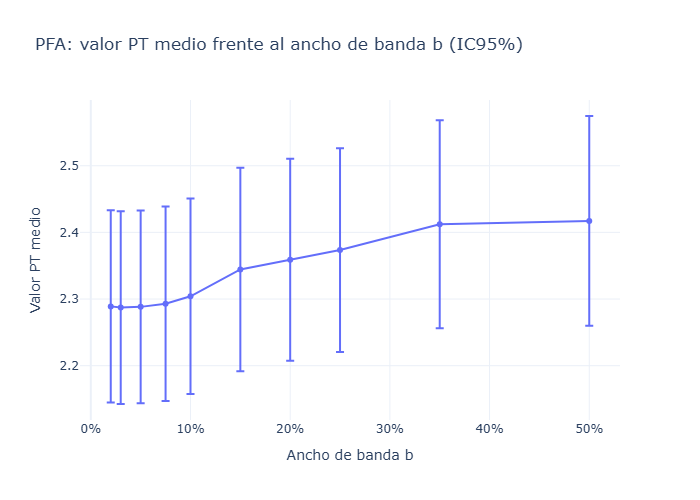

In [22]:
N_TUNE, CFA_TUNE_SCEN = 300, 150
tune_sc = block_bootstrap(hist, N_TUNE, seed=TUNE_SEED)

B_GRID = [0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.35, 0.50]
t0 = time.time()
pfa_tab = tune(lambda b: BandRebalancing(w_star, b), [{"b": b} for b in B_GRID], tune_sc, hist, REF, W0=W0, cost=COST)
b_star = float(pfa_tab.loc[0, "b"])
print(f"PFA ajustada en {time.time() - t0:.1f} s → b* = {b_star:.1%}")
display(pfa_tab.style.format({"b": "{:.1%}", "pt_mean": "{:.4f}", "pt_se": "{:.4f}",
                              "median_WT": "{:,.0f}", "mean_costs": "{:,.0f}"}))

fig = px.scatter(pfa_tab.sort_values("b"), x="b", y="pt_mean", error_y=1.96 * pfa_tab.sort_values("b")["pt_se"],
                 title="PFA: valor PT medio frente al ancho de banda b (IC95%)",
                 labels={"b": "Ancho de banda b", "pt_mean": "Valor PT medio"})
fig.update_traces(mode="lines+markers")
fig.update_layout(xaxis_tickformat=".0%", template="plotly_white")
fig.show()

CFA ajustada en 4.3 min → θ* = 1.25, N* = 120 meses


,theta,window,pt_mean,pt_se,median_WT,mean_costs
0,1.250000,120,1.9298,0.1298,"276,668",871
1,1.000000,120,1.8969,0.1096,"273,841",874
2,0.750000,120,1.7962,0.0862,"269,753",780
3,1.250000,60,1.6890,0.1241,"250,222","1,177"
4,1.000000,60,1.6656,0.1108,"251,419","1,228"
5,1.250000,36,1.5982,0.1211,"238,074","1,507"
6,0.750000,60,1.5885,0.0942,"250,359","1,288"
7,1.000000,36,1.5778,0.1184,"233,303","1,532"
8,0.750000,36,1.5112,0.1048,"222,135","1,580"


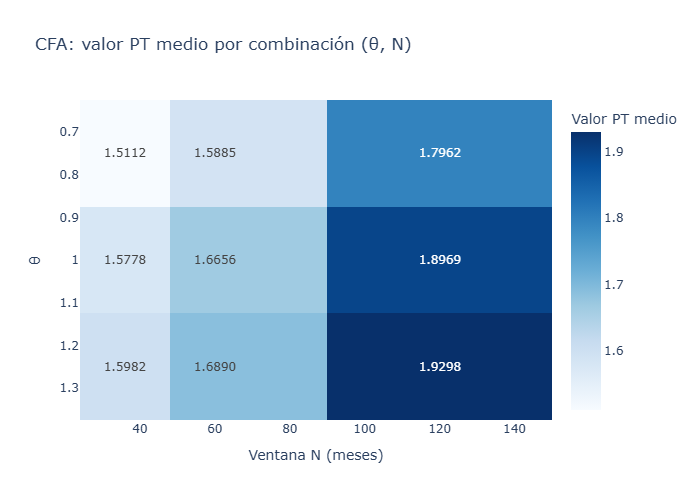

In [23]:
CFA_GRID = [{"theta": th, "window": n} for th in (0.75, 1.0, 1.25) for n in (36, 60, 120)]
t0 = time.time()
cfa_tab = tune(lambda theta, window: AnnualReoptimization(REF.lam, theta, window, CONS, A, hist),
               CFA_GRID, tune_sc.subset(CFA_TUNE_SCEN), hist, REF, W0=W0, cost=COST)
theta_star, window_star = float(cfa_tab.loc[0, "theta"]), int(cfa_tab.loc[0, "window"])
print(f"CFA ajustada en {(time.time() - t0) / 60:.1f} min → θ* = {theta_star}, N* = {window_star} meses")
display(cfa_tab.style.format({"pt_mean": "{:.4f}", "pt_se": "{:.4f}", "median_WT": "{:,.0f}", "mean_costs": "{:,.0f}"}))

heat = cfa_tab.pivot(index="theta", columns="window", values="pt_mean")
px.imshow(heat, text_auto=".4f", aspect="auto", color_continuous_scale="Blues",
          labels={"x": "Ventana N (meses)", "y": "θ", "color": "Valor PT medio"},
          title="CFA: valor PT medio por combinación (θ, N)").show()

In [24]:
tuned = {
    "b_star": b_star, "theta_star": theta_star, "window_star": window_star,
    "reference_profile": REF.as_dict(), "constraints": CONS.__dict__,
    "tune_seed": TUNE_SEED, "eval_seed": EVAL_SEED, "n_tune": N_TUNE, "n_tune_cfa": CFA_TUNE_SCEN,
}
with open("data/tuned_params.json", "w", encoding="utf-8") as fh:
    json.dump(tuned, fh, ensure_ascii=False, indent=2, default=float)
print(json.dumps({k: tuned[k] for k in ("b_star", "theta_star", "window_star")}, indent=2))

{
  "b_star": 0.5,
  "theta_star": 1.25,
  "window_star": 120
}


**Cómo leer el ajuste.** Si $b^*$ queda en el extremo superior de la cuadrícula, rebalancear no agrega valor para este cliente con los datos 2008–2026: con una banda tan ancha la PFA casi nunca opera y converge al baseline de comprar y mantener. Es un hallazgo, no un error. Cortar las posiciones ganadoras (tecnología y oro en este periodo) para volver a los pesos objetivo resta retorno, y los costos de transacción restan más. Lo mismo ocurre si $\theta^*$ queda en su máximo: los datos premian aceptar algo más de riesgo de cola. La sección 9 muestra si la conclusión cambia con otras condiciones.

## 8. Evaluación final (1000 escenarios, semilla 7777)

Las seis políticas se simulan sobre **el mismo** tensor de 1000 escenarios, que no se usó para ajustar. Para cada una reportamos:
- **la métrica principal**, el valor PT de la riqueza final: media, desviación estándar, P5/P95 e IC95% de la media (normal y bootstrap);
- **la riqueza final**: media, percentiles e IC;
- **diferencias pareadas** frente a la PFA, escenario por escenario. Aprovechan los números aleatorios comunes: la variabilidad del mercado se cancela y queda solo el efecto de la política.

In [25]:
N_EVAL = 1000
eval_sc = block_bootstrap(hist, N_EVAL, seed=EVAL_SEED)
assert eval_sc.seed != tune_sc.seed and N_EVAL >= 500

CFA_CFG = dict(theta=theta_star, window=window_star, cons=CONS, A=A, hist=hist)
t0 = time.time()
policies = standard_policies(REF, w_star, b_star, cash_idx, cfa=CFA_CFG)
results = evaluate(policies, eval_sc, hist, W0=W0, cost=COST)
print(f"Evaluación de {len(results)} políticas × {N_EVAL} escenarios en {(time.time() - t0) / 60:.1f} min")

table = results_table(results, REF, W0)
money = {c: "{:,.0f}" for c in table.columns if c.startswith("Riqueza") and "IC" not in c}
display(table.style.format({**money, "Valor PT medio": "{:.4f}", "Valor PT desv.": "{:.4f}",
                            "Valor PT P5": "{:.4f}", "Valor PT P95": "{:.4f}",
                            "Caída máx. mediana": "{:.1%}", "Costos medios": "{:,.0f}",
                            "Rotación anual media": "{:.1%}"}))

Evaluación de 6 políticas × 1000 escenarios en 3.4 min


,Clase,Valor PT medio,Valor PT desv.,Valor PT P5,Valor PT P95,IC95% PT (normal),IC95% PT (bootstrap),Riqueza final media,Riqueza desv.,Riqueza P5,Riqueza P50,Riqueza P95,IC95% riqueza media,Caída máx. mediana,Costos medios,Rotación anual media
Política,,,,,,,,,,,,,,,,
Comprar y mantener,Baseline,2.2864,1.3647,0.5564,4.8618,"[2.2018, 2.3709]","[2.2066, 2.3696]","362,799","177,481","151,370","326,297","703,183","[351,798, 373,799]",20.8%,100,5.4%
Rebalanceo por bandas,PFA,2.2867,1.3650,0.5564,4.8618,"[2.2021, 2.3713]","[2.2066, 2.3698]","362,839","177,515","151,370","326,297","703,183","[351,837, 373,841]",20.8%,101,5.4%
Re-optimización anual,CFA,1.9088,1.5492,0.1623,4.8468,"[1.8128, 2.0048]","[1.8188, 2.0050]","318,913","199,506","112,667","269,775","701,072","[306,548, 331,278]",29.6%,880,48.3%
Venta por pánico,Conductual,1.7190,1.6072,-0.3263,4.7845,"[1.6194, 1.8186]","[1.6204, 1.8198]","299,740","198,263","88,853","246,408","692,301","[287,451, 312,028]",20.4%,272,17.9%
Persecución de rendimiento,Conductual,1.9379,1.1644,0.4612,4.1359,"[1.8658, 2.0101]","[1.8702, 2.0081]","317,977","147,806","141,501","289,580","601,937","[308,816, 327,138]",19.8%,"1,908",102.7%
Tú tal como eres,Conductual (perfil),1.5130,1.3884,-0.3471,4.0935,"[1.4270, 1.5991]","[1.4263, 1.5999]","272,620","167,548","88,045","234,374","596,097","[262,236, 283,005]",19.8%,"1,621",88.2%


In [26]:
paired = paired_comparison(results, REF, W0, reference=PFA)
display(paired.style.format({"Δ valor PT medio": "{:.4f}", "Δ riqueza media (US$)": "{:,.0f}",
                             "Δ riqueza mediana (US$)": "{:,.0f}", f"Prob. de superar a «{PFA}»": "{:.0%}"}))

costs = behavior_costs(results, reference=PFA)
display(Markdown(f"**Costo de las conductas frente a la disciplina** (mismos {N_EVAL} escenarios)"))
display(costs.style.format({"Costo en la mediana (US$)": "{:,.0f}", "Costo medio (US$)": "{:,.0f}",
                            "Escenarios peores que la disciplina": "{:.0%}"}))

# Pruebas de la evaluación
s = summarize(pt_scores(results[PFA].terminal, W0, W0, REF))
assert s["ci_low"] <= s["mean"] <= s["ci_high"] and s["boot_low"] <= s["mean"] <= s["boot_high"]
assert summarize(results[PFA].terminal - results[PFA].terminal)["mean"] == 0
print("✓ Evaluación: pruebas pasan")

,Δ valor PT medio,IC95% Δ PT,¿Diferencia significativa?,Δ riqueza media (US$),IC95% Δ riqueza,Δ riqueza mediana (US$),Prob. de superar a «Rebalanceo por bandas»
Política,,,,,,,
Comprar y mantener,-0.0003,"[-0.0009, 0.0003]",no,-40,"[-119, 39]",0,0%
Re-optimización anual,-0.3778,"[-0.4219, -0.3337]",sí,"-43,926","[-49,702, -38,149]","-56,523",23%
Venta por pánico,-0.5677,"[-0.6221, -0.5132]",sí,"-63,099","[-69,549, -56,650]","-79,889",4%
Persecución de rendimiento,-0.3487,"[-0.3767, -0.3208]",sí,"-44,862","[-48,635, -41,088]","-36,717",18%
Tú tal como eres,-0.7736,"[-0.8256, -0.7217]",sí,"-90,219","[-96,493, -83,944]","-91,923",12%


**Costo de las conductas frente a la disciplina** (mismos 1000 escenarios)

,Costo en la mediana (US$),Costo medio (US$),IC95% costo medio,Escenarios peores que la disciplina
Conducta,,,,
Venta por pánico,"79,889","63,099","[56,650, 69,549]",49%
Persecución de rendimiento,"36,717","44,862","[41,088, 48,635]",82%
Tú tal como eres,"91,923","90,219","[83,944, 96,493]",88%


✓ Evaluación: pruebas pasan


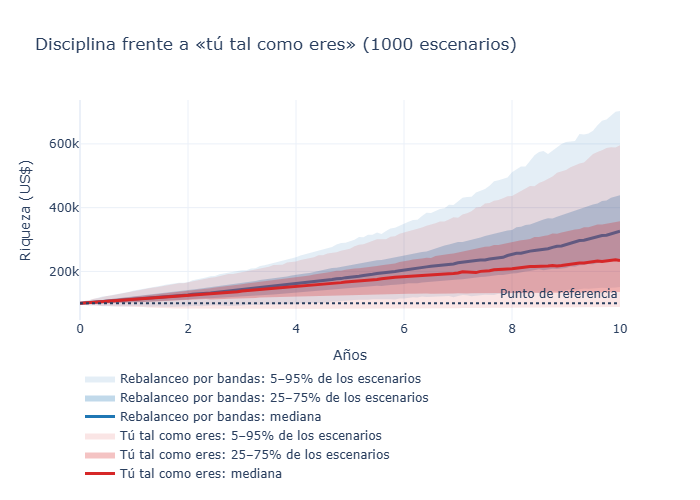

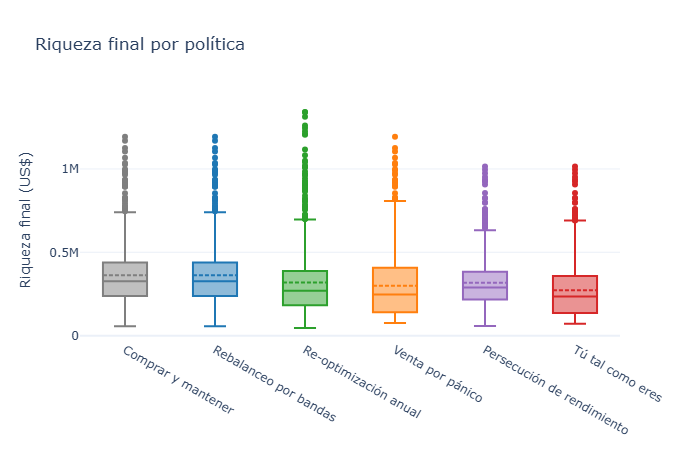

In [27]:
fan_figure(results, [PFA, CLIENT], W_ref=W0, title=f"Disciplina frente a «tú tal como eres» ({N_EVAL} escenarios)").show()
terminal_figure(results).show()

## 9. Sensibilidad y recomendación

¿Bajo qué condiciones cambia la recomendación? Repetimos la comparación entre las tres políticas que optimizan, sobre los primeros 300 escenarios de evaluación, cambiando una cosa a la vez:
- **la aversión a pérdidas λ**, que cambia el portafolio de la Parte 2, la CFA y la métrica;
- **los costos de transacción**: 50 pb en vez de 10 pb;
- **el punto de referencia**: una meta de 4% anual en vez de "no perder".

Los parámetros ajustados ($b^*$, $\theta^*$, $N^*$) se mantienen fijos; solo cambian las condiciones.

In [28]:
SENS_SCEN = 300
sens_sc = eval_sc.subset(SENS_SCEN)
CANDIDATES = [BH, PFA, CFA]        # de la más simple a la más compleja


def run_variant(prof, cost):
    port = build_portfolio(prof, rets, CONS)
    pols = standard_policies(prof, port.weights.to_numpy(), b_star, cash_idx, cfa=CFA_CFG)
    pols = [p for p in pols if p.name in CANDIDATES]
    return evaluate(pols, sens_sc, hist, W0=W0, cost=cost)


variants = {
    "Base (λ = 2.25, 10 pb, referencia = W0)": (REF, COST, W0),
    "Aversión baja (λ = 1)": (replace(REF, lam=1.0), COST, W0),
    "Aversión alta (λ = 4)": (replace(REF, lam=4.0), COST, W0),
    "Costos de 50 pb": (REF, 0.005, W0),
    "Meta de 4% anual": (REF, COST, W0 * 1.04 ** 10),
}
cache, rows = {}, []
t0 = time.time()
for label, (prof, cost, ref) in variants.items():
    key = (prof.lam, cost)
    if key not in cache:
        cache[key] = run_variant(prof, cost)
    rec = recommend(cache[key], prof, W0, ref, CANDIDATES)
    rows.append({"Escenario": label, **{f"PT medio · {n}": v for n, v in rec["means"].items()},
                 "Mayor PT": rec["best"], "Recomendada": rec["chosen"]})
sens = pd.DataFrame(rows).set_index("Escenario")
print(f"Sensibilidad en {(time.time() - t0) / 60:.1f} min")
display(sens.style.format({c: "{:.4f}" for c in sens.columns if c.startswith("PT")}))

Sensibilidad en 3.6 min


,PT medio · Comprar y mantener,PT medio · Rebalanceo por bandas,PT medio · Re-optimización anual,Mayor PT,Recomendada
Escenario,,,,,
"Base (λ = 2.25, 10 pb, referencia = W0)",2.2402,2.2402,1.8868,Comprar y mantener,Comprar y mantener
Aversión baja (λ = 1),2.3450,2.3450,1.8821,Comprar y mantener,Comprar y mantener
Aversión alta (λ = 4),1.6634,1.6598,1.5958,Comprar y mantener,Comprar y mantener
Costos de 50 pb,2.2290,2.2290,1.8348,Comprar y mantener,Comprar y mantener
Meta de 4% anual,1.8307,1.8307,1.4117,Comprar y mantener,Comprar y mantener


In [29]:
rec = recommend(results, REF, W0, W0, CANDIDATES)
pt_tab = results_table(results, REF, W0)
base_label = next(iter(variants))
changes = [f"- **{lbl}:** la recomendación pasa a ser «{row['Recomendada']}»."
           for lbl, row in sens.iterrows() if row["Recomendada"] != sens.loc[base_label, "Recomendada"]]
cost_line = costs.loc[CLIENT, "Costo en la mediana (US$)"] if CLIENT in costs.index else float("nan")

text = f"""### Recomendación

**Recomendamos «{rec['chosen']}»** para el cliente de referencia: {rec['reason']}.

- Valor PT medio por política ({N_EVAL} escenarios de evaluación): {'; '.join(f'{n}: {v:.4f}' for n, v in rec['means'].items())}.
- IC95% del valor PT de la política recomendada: {pt_tab.loc[rec['chosen'], 'IC95% PT (normal)']}.
- Mediana de la riqueza final con la política recomendada: {usd(pt_tab.loc[rec['chosen'], 'Riqueza P50'])}; percentiles 5–95: {usd(pt_tab.loc[rec['chosen'], 'Riqueza P5'])} a {usd(pt_tab.loc[rec['chosen'], 'Riqueza P95'])}.
- **El comportamiento pesa más que la regla:** los sesgos del cliente de referencia (pánico + persecución) le cuestan {usd(cost_line)} en la mediana frente a la disciplina.

**Cuándo cambiaría esta recomendación** (análisis de sensibilidad, {SENS_SCEN} escenarios):
{chr(10).join(changes) if changes else '- En ninguna de las variantes probadas cambia la política recomendada.'}
- Si el cliente no puede seguir la regla durante las caídas, la prioridad es la disciplina (acompañamiento, reglas automáticas) antes que elegir entre PFA y CFA: el costo de los sesgos es mayor que la diferencia entre reglas.
- Si cambia el universo o el régimen de mercado (por ejemplo, tasas mucho más altas o más bajas que en 2008–2026), hay que volver a ajustar los parámetros con datos nuevos.
"""
display(Markdown(text))

### Recomendación

**Recomendamos «Comprar y mantener»** para el cliente de referencia: no es significativamente peor que «Rebalanceo por bandas» (el IC95% de la diferencia de valor PT, [-0.0009, 0.0003], incluye 0) y es más simple de seguir.

- Valor PT medio por política (1000 escenarios de evaluación): Comprar y mantener: 2.2864; Rebalanceo por bandas: 2.2867; Re-optimización anual: 1.9088.
- IC95% del valor PT de la política recomendada: [2.2018, 2.3709].
- Mediana de la riqueza final con la política recomendada: US$ 326.297; percentiles 5–95: US$ 151.370 a US$ 703.183.
- **El comportamiento pesa más que la regla:** los sesgos del cliente de referencia (pánico + persecución) le cuestan US$ 91.923 en la mediana frente a la disciplina.

**Cuándo cambiaría esta recomendación** (análisis de sensibilidad, 300 escenarios):
- En ninguna de las variantes probadas cambia la política recomendada.
- Si el cliente no puede seguir la regla durante las caídas, la prioridad es la disciplina (acompañamiento, reglas automáticas) antes que elegir entre PFA y CFA: el costo de los sesgos es mayor que la diferencia entre reglas.
- Si cambia el universo o el régimen de mercado (por ejemplo, tasas mucho más altas o más bajas que en 2008–2026), hay que volver a ajustar los parámetros con datos nuevos.


**Limitaciones.**
- El bootstrap y el MILP de la Parte 2 usan la misma historia, así que el portafolio "conoce" la distribución de la que se sortean los escenarios. La ventana móvil de la CFA mitiga esto en parte, porque incorpora los meses simulados.
- El cuestionario no está validado con personas reales.
- No modelamos impuestos, aportes, retiros ni inflación.
- La ponderación de probabilidades de prospect theory acumulativa queda fuera por diseño.

## 10. Dashboard de Streamlit

La app usa el mismo paquete `core`. Carga los retornos y los parámetros ajustados que guardó este notebook (`data/`), así que no depende de yfinance durante la reunión con el cliente. Tiene cuatro pestañas:

1. **Cuestionario:** las 11 preguntas y el perfil estimado, explicado en frases.
2. **Mi portafolio:** la decisión recomendada de hoy (qué comprar y cuánto), su composición por clase y la pérdida típica en meses malos.
3. **Mi futuro:** gráfico de abanico de 500 futuros simulados, con disciplina y "tú tal como eres".
4. **Comparar reglas:** la recomendación, el costo en dinero de cada sesgo y la comparación de políticas en lenguaje simple.

En la barra lateral el cliente cambia su riqueza inicial y su meta, y el asesor ajusta K, l, u, el tope por clase, λ, α, β y los sesgos. El MILP y la simulación corren en vivo y quedan en caché; la CFA, que es más lenta, se calcula al pulsar un botón.

In [30]:
%%writefile app.py
"""Dashboard de portafolio conductual: perfil → portafolio → futuro simulado → costo de los sesgos."""
import json
from dataclasses import replace

import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

from core import profile as qp
from core.data import UNIVERSE, CASH, load_returns
from core.portfolio import Constraints, build_portfolio, class_matrix
from core.scenarios import block_bootstrap, EVAL_SEED
from core.policies import standard_policies, BH, PFA, CFA, PANIC, CHASE, CLIENT
from core.evaluation import evaluate, results_table, behavior_costs, plain_language, recommend, usd
from core.plots import fan_figure, terminal_figure

APP_SCEN = 500
COST = 0.001

st.set_page_config(page_title="Tu plan de inversión", layout="wide")


@st.cache_data
def load_inputs():
    rets = load_returns("data/monthly_returns.csv")
    with open("data/tuned_params.json", encoding="utf-8") as fh:
        tuned = json.load(fh)
    return rets, tuned


rets, tuned = load_inputs()
tickers = list(rets.columns)
hist = rets.to_numpy(float)
cash_idx = tickers.index(CASH)
A = class_matrix(tickers, UNIVERSE)[0]


@st.cache_data(show_spinner="Optimizando tu portafolio con Gurobi…")
def cached_portfolio(lam, K, l, u, cap):
    return build_portfolio(lam, rets, Constraints(K=K, l=l, u=u, class_cap=cap))


@st.cache_data(show_spinner="Simulando 500 futuros posibles…")
def cached_results(w_star, prof_items, b, W0, include_cfa, theta, window, K, l, u, cap):
    prof = qp.Profile(**dict(prof_items))
    sc = block_bootstrap(hist, APP_SCEN, seed=EVAL_SEED)
    cfa = None
    if include_cfa:
        cfa = dict(theta=theta, window=window, cons=Constraints(K=K, l=l, u=u, class_cap=cap), A=A, hist=hist)
    pols = standard_policies(prof, np.array(w_star), b, cash_idx, cfa=cfa)
    return evaluate(pols, sc, hist, W0=W0, cost=COST)


if "answers" not in st.session_state:
    st.session_state.answers = dict(qp.DEFAULT_ANSWERS)

# ---------------- Barra lateral ----------------
with st.sidebar:
    st.header("Tus datos")
    W0 = float(st.number_input("Riqueza inicial (US$)", min_value=1_000, max_value=100_000_000,
                               value=100_000, step=5_000))
    use_goal = st.checkbox("Medir el éxito contra una meta de crecimiento")
    g = st.slider("Meta de crecimiento anual (%)", 0.0, 10.0, 4.0, 0.5, disabled=not use_goal) / 100
    W_ref = W0 * (1 + g) ** 10 if use_goal else W0

    st.header("Reglas del asesor")
    K = st.slider("Máximo de activos (K)", 3, 15, 8)
    l = st.slider("Posición mínima por activo (%)", 1, 10, 5) / 100
    u = st.slider("Posición máxima por activo (%)", 15, 60, 35) / 100
    cap = st.slider("Tope por clase de activo (%)", 30, 100, 50) / 100
    if K * u < 1:
        st.error("Con estos valores no se puede invertir el 100%: aumenta K o la posición máxima.")
        st.stop()

    with st.expander("Ajustar el perfil a mano (asesor)"):
        override = st.checkbox("Sobrescribir λ, α y β estimados")
        lam_o = st.slider("λ: aversión a pérdidas", 1.0, 5.0, 2.25, 0.05)
        a_o = st.slider("α: curvatura en ganancias", 0.2, 1.0, 0.88, 0.01)
        b_o = st.slider("β: curvatura en pérdidas", 0.2, 1.0, 0.88, 0.01)

p = qp.estimate_profile(st.session_state.answers)
if override:
    p = replace(p, lam=lam_o, alpha=a_o, beta=b_o)

with st.sidebar.expander("Sesgos: escenarios hipotéticos (asesor)"):
    bias_override = st.checkbox("Modificar los sesgos del perfil")
    panic_o = st.checkbox("Vende en pánico", value=p.panic)
    d_o = st.slider("Caída que dispara la venta (%)", 5, 40, int(round(p.d * 100))) / 100
    r_o = st.slider("Rebote para volver a invertir (%)", 0, 40, int(round(p.r * 100))) / 100
    phi_o = st.slider("Fracción que vende (%)", 10, 100, int(round(p.phi * 100)), 10) / 100
    chase_o = st.checkbox("Persigue rendimientos", value=p.chase)
    kappa_o = st.slider("Fracción que mueve a los ganadores (%)", 0, 100, int(round(p.kappa * 100)), 5) / 100
    f_opts = [1, 3, 6, 12]
    f_o = st.selectbox("Cada cuántos meses persigue", f_opts, index=f_opts.index(p.f) if p.f in f_opts else 1)
if bias_override:
    p = replace(p, panic=panic_o, d=d_o, r=r_o, phi=phi_o, chase=chase_o and kappa_o > 0,
                kappa=kappa_o if kappa_o > 0 else p.kappa, f=int(f_o))

st.title("Tu plan de inversión")
st.caption("Herramienta educativa: los resultados son simulaciones con datos históricos 2008–2026, no promesas.")
tab1, tab2, tab3, tab4 = st.tabs(["1. Cuestionario", "2. Mi portafolio", "3. Mi futuro", "4. Comparar reglas"])

# ---------------- 1. Cuestionario ----------------
with tab1:
    st.subheader("Cuestionario (11 preguntas)")
    st.write("No hay respuestas correctas. Responde pensando en tu propio dinero.")
    saved = st.session_state.answers
    with st.form("quiz"):
        ans = {}
        st.markdown("#### Apuestas con ganancias y pérdidas")
        for q in qp.LAMBDA_QUESTIONS:
            opts = qp.lambda_options(q["loss"])
            labels = [o[0] for o in opts]
            idx = next((i for i, o in enumerate(opts) if o[1] == saved.get(q["id"])), 2)
            choice = st.radio(qp.lambda_text(q["loss"]), labels, index=idx)
            ans[q["id"]] = opts[labels.index(choice)][1]
        st.markdown("#### Ganancias seguras o apuestas")
        for q in qp.ALPHA_QUESTIONS:
            ans[q["id"]] = st.slider(qp.alpha_text(q["stake"]), 0.0, float(q["stake"]),
                                     float(saved[q["id"]]), 0.5, format="%.1f%%")
        st.markdown("#### Pérdidas seguras o apuestas")
        for q in qp.BETA_QUESTIONS:
            ans[q["id"]] = st.slider(qp.beta_text(q["stake"]), 0.0, float(q["stake"]),
                                     float(saved[q["id"]]), 0.5, format="%.1f%%")
        st.markdown("#### ¿Qué harías?")
        for q in qp.BIAS_QUESTIONS:
            choice = st.radio(q["text"], q["options"], index=int(saved[q["id"]]))
            ans[q["id"]] = q["options"].index(choice)
        if st.form_submit_button("Calcular mi perfil", type="primary"):
            st.session_state.answers = ans
            st.rerun()

    st.subheader("Tu perfil")
    c1, c2, c3 = st.columns(3)
    c1.metric("Aversión a pérdidas λ", f"{p.lam:.2f}")
    c2.metric("Curvatura en ganancias α", f"{p.alpha:.2f}")
    c3.metric("Curvatura en pérdidas β", f"{p.beta:.2f}")
    for line in qp.describe_profile(p):
        st.markdown(f"- {line}")
    if not np.isnan(p.lam_curv):
        st.caption(f"λ corregido por la curvatura de tus respuestas: {p.lam_curv:.2f} (informativo).")

# ---------------- Cálculos ----------------
port = cached_portfolio(p.lam, K, l, u, cap)
w_star = port.weights.to_numpy()
include_cfa = st.session_state.get("cfa", False)
res = cached_results(tuple(np.round(w_star, 10)), tuple(sorted(p.as_dict().items())), float(tuned["b_star"]),
                     W0, include_cfa, float(tuned["theta_star"]), int(tuned["window_star"]), K, l, u, cap)
b_star = float(tuned["b_star"])
candidates = [BH, PFA] + ([CFA] if include_cfa else [])
rec = recommend(res, p, W0, W_ref, candidates)
HOW_TO = {
    BH: "**Cómo mantenerlo:** compra hoy estos montos y mantenlos. En las simulaciones, rebalancear no mejoró "
        "tu resultado, así que no necesitas operar cada mes. Revisa tu plan una vez al año o si cambian tus metas.",
    PFA: f"**Cómo mantenerlo:** revisa tu portafolio una vez al mes. Si algún activo se aleja más de "
         f"{b_star:.1%} de su peso objetivo, vuelve a los pesos de esta tabla. Si no, no hagas nada.",
    CFA: "**Cómo mantenerlo:** una vez al año, vuelve a calcular el portafolio con los datos más recientes "
         "(esta app lo hace por ti) y ajusta tus posiciones a la nueva tabla.",
}

# ---------------- 2. Mi portafolio ----------------
with tab2:
    st.subheader("Tu decisión de hoy: qué comprar")
    c1, c2, c3 = st.columns(3)
    c1.metric("Activos en el portafolio", int((w_star > 0).sum()))
    c2.metric("Retorno anual esperado (histórico)", f"{(1 + port.mean) ** 12 - 1:.1%}")
    c3.metric("Pérdida promedio en el peor 5% de los meses", f"{port.cvar:.1%}")
    st.caption(f"Tu límite de pérdida en meses malos (CVaR 95%) es {port.cvar_limit:.1%} al mes; lo fija tu aversión "
               f"a pérdidas λ = {p.lam:.2f}. Estado del optimizador: {port.status}.")
    tbl = port.table(W0)
    left, right = st.columns([3, 2])
    left.dataframe(tbl.style.format({"Peso": "{:.1%}", "Monto a invertir (US$)": "{:,.0f}"}),
                   use_container_width=True)
    by_class = tbl.groupby("Clase", as_index=False)["Peso"].sum()
    right.plotly_chart(px.pie(by_class, names="Clase", values="Peso", hole=0.5, title="Por clase de activo"),
                       use_container_width=True)
    st.info(HOW_TO[rec["chosen"]])

# ---------------- 3. Mi futuro ----------------
with tab3:
    st.subheader("500 futuros posibles para tu dinero")
    st.plotly_chart(fan_figure(res, [PFA, CLIENT], W_ref=W_ref,
                               title="Con disciplina (azul) y tal como eres (rojo)"), use_container_width=True)
    st.markdown("La línea gruesa es el resultado **típico** (la mitad de los escenarios termina por encima). "
                "La banda oscura contiene la mitad central de los escenarios y la banda clara, el 90%.")
    if np.allclose(res[CLIENT].terminal, res[PFA].terminal):
        st.success("No detectamos sesgos: tu comportamiento coincide con la regla disciplinada.")

# ---------------- 4. Comparar reglas ----------------
with tab4:
    st.subheader("Nuestra recomendación")
    st.success(f"**{rec['chosen']}**: {rec['reason']}.")
    if not include_cfa:
        if st.button("Incluir también la re-optimización anual (puede tardar 2–5 minutos)"):
            st.session_state.cfa = True
            st.rerun()

    st.subheader("¿Cuánto te cuesta tu comportamiento?")
    bc = behavior_costs(res, reference=PFA)
    cols = st.columns(len(bc))
    flags = {PANIC: p.panic, CHASE: p.chase, CLIENT: p.panic or p.chase}
    for col, (name, row) in zip(cols, bc.iterrows()):
        label = name if flags.get(name, True) else f"{name} (hipotético)"
        col.metric(label, usd(-row["Costo en la mediana (US$)"]),
                   help=f"Cambio en tu riqueza final típica frente a «{PFA}». Peor que la disciplina en "
                        f"{row['Escenarios peores que la disciplina']:.0%} de los escenarios.")
    st.caption("Un número negativo es dinero que pierdes, en el resultado típico a 10 años, por actuar así en vez de "
               "seguir la regla de bandas. «Hipotético» significa que no detectamos ese sesgo en tus respuestas.")

    st.subheader("Las reglas en palabras simples")
    for name, sentence in plain_language(res, W0, W_ref, reference=PFA).items():
        st.markdown(f"**{name}.** {sentence}")

    st.plotly_chart(terminal_figure(res), use_container_width=True)

    st.subheader("¿Cuándo cambiaría la recomendación?")
    st.markdown(
        "- **Si tus costos de transacción suben mucho**, la regla de no operar (comprar y mantener) gana terreno.\n"
        "- **Si cambia tu aversión a pérdidas**, cambia tu portafolio: vuelve a responder el cuestionario.\n"
        "- **Si no puedes seguir la regla en las caídas**, lo más importante es la disciplina: el costo de los "
        "sesgos suele ser mayor que la diferencia entre reglas.\n"
        "- **Si cambia el mercado** respecto de 2008–2026, el asesor debe volver a ajustar los parámetros.")

    with st.expander("Detalle estadístico (para el asesor)"):
        st.dataframe(results_table(res, p, W0, W_ref), use_container_width=True)

Overwriting app.py


### Lanzar la app

**En línea:** el dashboard está publicado en Streamlit Community Cloud (el enlace está en el README del repositorio) y se abre desde cualquier navegador, también en el celular.

**En local:** desde la carpeta del repositorio, con el entorno activado:

```
streamlit run app.py
```

La app necesita `data/monthly_returns.csv` y `data/tuned_params.json`, que este notebook genera (y que ya vienen incluidos en el repositorio).